# Machine learning for neural time series — hands-on

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gon-uri/ITBA2026/blob/main/notebook/ml_neural_ts_notebook.ipynb)

*ITBA · 23 October 2026 · Gonzalo Uribarri (Stockholm University)*

**Two questions for today**
- **Q1 (EEG):** *Can a model tell from the EEG whether your eyes are closed, in a person it has never seen?*
- **Q2 (fMRI):** *Can a model tell a child's brain from an adult's — and is it reading the brain or the head movement?*
- Q3 (spikes, *where is the rat?*) is in Part B, for home.

**How to work**
- In pairs, one laptop. **Shift+Enter** runs a cell. There is no code to write: read, predict, run, look.
- Before each result, **say your guess to your partner**, then run the cell.
- If Colab says "This notebook was not authored by Google", click *Run anyway*.
- If you fall behind: *Runtime → Run all*, then read the results in order.
- **Jump rule: when the professor says "jump", go to §6 (fMRI)**, even if the EEG part is not finished. §6–§8 need
  only §0. You can finish §1–§5 at home.

**Two tasks.** **PREDICT · classify or regress:** learn a category or a number from labelled examples.
**REPRESENT · embed or cluster:** find a compact description of the data without labels. A **graph** of the channels
(a connectome) is not a third task: it is one more way to turn a multichannel series into features (**connectivity
features**).

| § | Task | Data | Question |
|---|---|---|---|
| §1 | look | EEG | What changes when the eyes close? |
| §2 | PREDICT · classify | EEG | Eyes open or closed, in a new person? How much does the test split matter? |
| §3 | REPRESENT · embed or cluster | EEG | What organises 1,200 windows when nobody gives labels? |
| §4 | look · connectivity features | EEG | Does closing the eyes change the alpha network? |
| §5 | puzzle | EEG | How can the forehead know that the eyes are closed? |
| §6 | PREDICT · classify (connectivity features) | fMRI | Child or adult from a brain graph? Is it head motion? |
| §7 | PREDICT · regress (connectivity features) | fMRI | How old is this brain? |
| §8 | your numbers | — | The table we discuss together at the end |
| Part B | at home | spikes, fMRI, sleep EEG, EEG, simulated | Q3 and five more |

**What depends on what.** Every section needs §0.1–§0.2. §1–§5 need the EEG of §0.3–§0.4, and §2–§5 also need the
spectra of §1.3 and the features of §2.1. §6–§8 need only §0.1–§0.3 (the fMRI file is downloaded in §0.3). Cells marked
*optional — skip in class* can be skipped without breaking anything.

Every result prints **your run** next to the **lecture run** (the number on the slides). They should agree.

*Data:* EEG — Schalk et al. 2004, EEG Motor Movement/Imagery dataset (PhysioNet), ODC-By 1.0. fMRI — Richardson et al.
2018, OpenNeuro ds000228, preprocessed derivative distributed with nilearn (OSF 5hju4), CC BY 4.0. Part B datasets
are credited in their sections. *Code:* MIT licence.

## §0 · Setup

**§0.1 · Install.** Colab already has numpy, scipy, scikit-learn, pandas and matplotlib. We add MNE (EEG) and nilearn
(fMRI). Read the questions above while it runs.

In [1]:
# §0.1 · Install the two packages Colab does not have: MNE (EEG) and nilearn (fMRI).
# The versions are pinned on purpose. Newer versions upgrade packages that Colab has already loaded
# (MNE >= 1.12 upgrades "decorator"; nilearn >= 0.14 upgrades pandas and requests), and Colab then asks
# you to restart the session.
%pip install -q mne==1.11.0 nilearn==0.13.1

**§0.2 · Imports, settings and small helpers.** `show()` prints your number next to the lecture's; `note()` keeps
your number for the table of §8.

In [2]:
# §0.2 · Imports, settings, helpers
import os, json, time, warnings, importlib.resources, concurrent.futures
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import scipy
from scipy.signal import welch, hilbert
from scipy.fft import next_fast_len
from scipy.ndimage import gaussian_filter1d
from scipy.stats import wilcoxon, spearmanr, mannwhitneyu, pearsonr, binom
import pooch
import mne
from mne.datasets import eegbci
import nilearn
from nilearn.connectome import ConnectivityMeasure
from nilearn import plotting
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import (GroupKFold, KFold, StratifiedKFold, RepeatedStratifiedKFold, RepeatedKFold,
                                     LeaveOneGroupOut, cross_val_score, cross_val_predict, cross_validate)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (silhouette_score, adjusted_rand_score, normalized_mutual_info_score, r2_score,
                             mean_absolute_error, balanced_accuracy_score, confusion_matrix)

mne.set_log_level("ERROR")
pooch.get_logger().setLevel("WARNING")

SEED = 0                                   # one seed everywhere, so your numbers match the lecture's
if "MNE_DATA" in os.environ:               # where downloads go
    DATA_DIR = Path(os.environ["MNE_DATA"])
elif Path("/content").is_dir():            # Google Colab
    DATA_DIR = Path("/content/data")
else:                                      # your own computer
    DATA_DIR = Path.home() / "mne_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# EEG settings (the same as in the lecture)
SUBJECTS = range(1, 21)                    # 20 volunteers, S001-S020
SFREQ = 160.0                              # samples per second
WIN_S = 2.0                                # window length (s)
OCC = ["O1", "Oz", "O2"]                   # back of the head (visual cortex)
FRONT = ["Fp1", "Fpz", "Fp2"]              # forehead
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}
ALPHA = (8, 13)                            # alpha band of the features
ALPHA_ENV = (8, 12)                        # alpha band of the envelope graph (§4)
SLOW_FRONT = (1, 3)                        # slow frontal power (§5.2)

# Colours of the slides
NAVY, ORANGE, STEEL, GREYBLUE, OLIVE, LIGHTBLUE = "#002F5F", "#EB7125", "#33587F", "#9BB2CE", "#A3A86B", "#ACDEE6"
EO_C, EC_C = NAVY, ORANGE                  # eyes open = navy, eyes closed = orange
ADULT_C, CHILD_C = NAVY, GREYBLUE          # fMRI groups
DIVERGING = LinearSegmentedColormap.from_list("steel_white_orange", [STEEL, "white", ORANGE])
WHITE_NAVY = LinearSegmentedColormap.from_list("white_navy", ["white", NAVY])
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

REPO_RAW = "https://raw.githubusercontent.com/gon-uri/ITBA2026/main/data/"
SHA256 = {
    "fmri_development_msdl.npz": '9cf96e73b8a8ba1034d32e7f96fc75b9142f1acf3e992ea349d8dabbbdb01518',
    "eoec_features.npz": '48564036f85d8feddb2f791d69da78fb12d17be23f114d61721c5221f16731cf',
    "achilles_dandi000044_maze_25ms.npz": '77585aba3306072d205a323755bb0fffb32a0a441e81a116d4c400567bc33413',
    "fmri_haxby_subj2_vt.npz": '468c1605c0cba2974f286a8f7691df4fdb619ef89b6712f9a631ff135e7d8cb4',
    "sleep8_feat.npz": 'c518551bc668be8b5c681fc53e55504b11fbb45f2dbf5ad8f8a007c8c19a2bd1',
}

# Numbers of the lecture run (Lesson/figures/results_*.json); do not edit
EXPECTED = {
    "ARI_random_relabel_k5": 0.0,
    "alpha_ratio_max": 21.12,
    "alpha_ratio_median": 3.37,
    "alpha_ratio_min": 1.12,
    "alpha_ratio_n_below_1": 0,
    "best_k_by_silhouette": 5,
    "clf_dummy_most_frequent_honest_mean": 0.5,
    "clf_dummy_most_frequent_honest_sd": 0.0,
    "clf_dummy_most_frequent_leaky_mean": 0.48,
    "clf_frontal_Fp1_Fpz_Fp2_all_freqs_honest_mean": 0.7525,
    "clf_frontal_Fp1_Fpz_Fp2_all_freqs_honest_sd": 0.0397,
    "clf_frontal_delta_1_3Hz_mean_logpower_honest_mean": 0.6125,
    "clf_frontal_delta_1_3Hz_mean_logpower_honest_sd": 0.0836,
    "clf_frontal_without_8_13Hz_honest_mean": 0.7117,
    "clf_frontal_without_8_13Hz_honest_sd": 0.0389,
    "clf_full_logpsd_64x40_honest_folds": [0.8042, 0.7375, 0.7542, 0.9, 0.5417],
    "clf_full_logpsd_64x40_honest_mean": 0.7475,
    "clf_full_logpsd_64x40_honest_per_subject_acc_max": 1.0,
    "clf_full_logpsd_64x40_honest_per_subject_acc_median": 0.733,
    "clf_full_logpsd_64x40_honest_per_subject_acc_min": 0.5,
    "clf_full_logpsd_64x40_honest_sd": 0.1175,
    "clf_full_logpsd_64x40_honest_subject_bootstrap95ci": [0.667, 0.83],
    "clf_full_logpsd_64x40_leaky_mean": 0.9117,
    "clf_full_logpsd_64x40_leaky_sd": 0.0218,
    "clf_full_logpsd_64x40_subjectz_honest_mean": 0.9167,
    "clf_full_logpsd_64x40_subjectz_honest_sd": 0.0372,
    "clf_leak_gain_full_logpsd_points": 16.4,
    "clf_occipital_O1_Oz_O2_alpha_bins_honest_mean": 0.72,
    "clf_occipital_O1_Oz_O2_alpha_bins_honest_sd": 0.0775,
    "clf_one_feature_occipital_alpha_mean_logpower_honest_mean": 0.6425,
    "clf_one_feature_occipital_alpha_mean_logpower_honest_sd": 0.0756,
    "clf_one_feature_occipital_alpha_mean_logpower_subjectz_honest_mean": 0.8283,
    "clf_one_feature_occipital_alpha_mean_logpower_subjectz_honest_sd": 0.0726,
    "clf_tangent_nilearn_honest_folds": [0.7167, 0.7958, 0.7792, 0.9167, 0.75],
    "clf_tangent_nilearn_honest_mean": 0.7917,
    "clf_tangent_nilearn_honest_sd": 0.0681,
    "cluster_kmeans_raw_k20_ari_eyes": 0.046,
    "cluster_kmeans_raw_k20_ari_person": 0.488,
    "cluster_kmeans_raw_k2_ari_eyes": -0.001,
    "cluster_kmeans_raw_k2_ari_person": 0.081,
    "cluster_kmeans_raw_k2_n_people_ge90pct_windows_in_one_cluster": 19,
    "cluster_kmeans_subjectz_k2_ari_eyes": 0.513,
    "cluster_kmeans_subjectz_k2_ari_person": -0.001,
    "decoding_direction.honest_logreg.balanced_accuracy_pooled": 0.9181,
    "decoding_direction.leaky_logreg.balanced_accuracy_pooled": 0.9669,
    "decoding_direction.majority_rate": 0.547,
    "decoding_position.honest_baseline_train_mean.mae_cm_pooled": 42.39,
    "decoding_position.honest_baseline_train_mean.r2_pooled": -0.005,
    "decoding_position.honest_knn10.mae_cm_pooled": 12.86,
    "decoding_position.honest_knn10.r2_pooled": 0.8223,
    "decoding_position.honest_ridgecv.r2_pooled": 0.8019,
    "decoding_position.leaky_knn10.mae_cm_pooled": 6.37,
    "decoding_position.leaky_knn10.r2_pooled": 0.9494,
    "decoding_position.leaky_ridgecv.r2_pooled": 0.8488,
    "dev_age_all_mae_model_mean_y": 3.5489,
    "dev_age_all_mae_model_sd_y": 0.5523,
    "dev_age_all_mae_trainmean_baseline_mean_y": 6.1937,
    "dev_age_all_pearson_r_mean": 0.7976,
    "dev_age_children_mae_model_mean_y": 1.3154,
    "dev_age_children_mae_trainmean_baseline_mean_y": 2.0374,
    "dev_age_children_pearson_r_mean": 0.7443,
    "dev_cls_all_correlation_acc_mean": 0.9542,
    "dev_cls_all_correlation_auc_mean": 0.9589,
    "dev_cls_all_correlation_bal_acc_mean": 0.9096,
    "dev_cls_all_correlation_bal_acc_sd": 0.0729,
    "dev_cls_all_dummy_acc_mean": 0.7871,
    "dev_cls_all_dummy_auc_mean": 0.5,
    "dev_cls_all_dummy_bal_acc_mean": 0.5,
    "dev_cls_all_motion_only_auc_mean": 0.7534,
    "dev_cls_all_motion_only_bal_acc_mean": 0.6927,
    "dev_cls_all_tangent_acc_mean": 0.9619,
    "dev_cls_all_tangent_auc_mean": 0.9628,
    "dev_cls_all_tangent_bal_acc_mean": 0.9201,
    "dev_cls_all_tangent_bal_acc_sd": 0.0613,
    "dev_cls_matched_correlation_auc_mean": 0.9584,
    "dev_cls_matched_correlation_bal_acc_mean": 0.9117,
    "dev_cls_matched_motion_only_auc_mean": 0.3878,
    "dev_cls_matched_motion_only_bal_acc_mean": 0.4317,
    "dev_cls_matched_tangent_auc_mean": 0.9632,
    "dev_cls_matched_tangent_bal_acc_mean": 0.9157,
    "dev_example_adult_typical_index": 25,
    "dev_example_child_typical_index": 150,
    "dev_fd_children_vs_adults_mannwhitney_p": 8.00366671909149e-06,
    "dev_fd_mean_adults_mean_mm": 0.1871,
    "dev_fd_mean_children_mean_mm": 0.3707,
    "dev_matched_fd_adults_mean_mm": 0.1871,
    "dev_matched_fd_children_mean_mm": 0.1883,
    "dev_meanconn_mean_offdiag_adults": 0.0869,
    "dev_meanconn_mean_offdiag_children": 0.1146,
    "dev_n_adults": 33,
    "dev_n_children": 122,
    "dev_pca_explained_variance_ratio_pc1": 0.0499,
    "dev_pca_spearman_pc1_age_all": 0.625,
    "dev_pca_spearman_pc1_age_children": 0.3484,
    "dev_pca_spearman_pc1_meanfd_all": -0.7128,
    "embed_raw_pca_explained_variance_pc1_pc2": [0.5, 0.075],
    "embed_raw_pca_silhouette_by_condition": 0.059,
    "embed_raw_pca_silhouette_by_subject": 0.007,
    "embed_raw_tsne_silhouette_by_condition": 0.048,
    "embed_raw_tsne_silhouette_by_subject": 0.321,
    "embed_subjectz_tsne_silhouette_by_condition": 0.334,
    "embed_subjectz_tsne_silhouette_by_subject": -0.119,
    "embedding.honest_knn10_from_pca3d.r2_pooled": 0.8209,
    "embedding.pca_evr_pc1_pc2_pc3_percent": [5.4, 4.4, 3.7],
    "facts.maze_epoch_duration_min": 34.46,
    "facts.n_bins_running": 9563,
    "facts.n_full_traversals_ge_120cm_left": 39,
    "facts.n_full_traversals_ge_120cm_right": 34,
    "facts.time_running_min": 3.98,
    "frontal_delta_n_subjects_EO_greater_than_EC": 16,
    "frontal_delta_power_ratio_EO_over_EC_geometric_mean": 3.456,
    "frontal_delta_wilcoxon_p_two_sided": 0.000483,
    "graph.frac_edges_within_20cm": 0.698,
    "graph.median_peak_distance_cm_all_pairs": 60.0,
    "graph.median_peak_distance_cm_edges": 10.0,
    "graph.n_edges": 351,
    "graph_aec_mean_offdiag_eyes_closed": 0.4145,
    "graph_aec_mean_offdiag_eyes_open": 0.4293,
    "graph_aec_n_subjects_EC_greater_than_EO": 10,
    "graph_aec_spearman_vs_distance_ec": -0.851,
    "graph_aec_spearman_vs_distance_eo": -0.886,
    "graph_aec_top5pct_frac_edges_shorter_than_5cm": 0.743,
    "graph_aec_top5pct_median_distance_cm": 3.82,
    "graph_aec_top5pct_n_edges_eyes_closed": 116,
    "graph_aec_top5pct_n_edges_eyes_open": 86,
    "graph_aec_top5pct_n_edges_in_both": 81,
    "graph_aec_top5pct_threshold_pooled": 0.8192,
    "graph_aec_wilcoxon_p_two_sided": 0.596,
    "graph_allpairs_median_distance_cm": 12.68,
    "graph_nearest_neighbour_distance_cm_median": 3.09,
    "graph_occipital_alpha_8_12_power_ratio_EC_over_EO_of_group_means": 6.35,
    "graph_occipital_alpha_8_12_power_uV2perHz_eyes_closed": 158.054,
    "graph_occipital_alpha_8_12_power_uV2perHz_eyes_open": 24.899,
    "haxby_8way_leave_one_run_out_acc_mean": 0.7269,
    "haxby_8way_leave_one_run_out_acc_sd": 0.0681,
    "haxby_8way_logo_recall_bottle": 0.5741,
    "haxby_8way_logo_recall_cat": 0.8148,
    "haxby_8way_logo_recall_chair": 0.6667,
    "haxby_8way_logo_recall_face": 0.8241,
    "haxby_8way_logo_recall_house": 0.9537,
    "haxby_8way_logo_recall_scissors": 0.463,
    "haxby_8way_logo_recall_scrambledpix": 0.8796,
    "haxby_8way_logo_recall_shoe": 0.6389,
    "haxby_8way_shuffled_kfold12_volumes_acc_mean": 0.8484,
    "haxby_8way_shuffled_kfold12_volumes_acc_sd": 0.028,
    "haxby_bottle_vs_scissors_leave_one_run_out_acc_mean": 0.7037,
    "haxby_bottle_vs_scissors_leave_one_run_out_acc_sd": 0.2818,
    "haxby_face_vs_house_leave_one_run_out_acc_mean": 1.0,
    "haxby_face_vs_house_leave_one_run_out_acc_sd": 0.0,
    "k5.ARI": 0.259,
    "k5.NMI": 0.417,
    "k5.purity": 0.635,
    "leakdemo_selection_inside_cv_rep0_mean": 0.54,
    "leakdemo_selection_outside_cv_rep0_mean": 0.95,
    "lr1_final_b": 0.0129,
    "lr1_final_loss": 0.59982,
    "lr1_final_w": 0.9713,
    "lr1_loss_iter0": 0.6931,
    "lr1_loss_iter20": 0.6014,
    "lr1_loss_iter5": 0.6288,
    "lr1_n_windows_above_threshold_eyes_open": 211,
    "lr1_n_windows_below_threshold_eyes_closed": 211,
    "lr1_sklearn_C1_lecture_protocol_b": 0.0126,
    "lr1_sklearn_C1_lecture_protocol_w": 0.9662,
    "lr1_sklearn_penalty_none_b": 0.0129,
    "lr1_sklearn_penalty_none_w": 0.9715,
    "lr1_threshold_uV2perHz": 17.521,
    "lr1_train_acc": 0.6483,
    "noise_N200_acc_max": 0.635,
    "noise_N200_acc_p95": 0.57,
    "noise_N200_acc_sd": 0.045,
    "noise_N200_binomial_p05_threshold_strict_acc": 0.565,
    "noise_N200_frac_reps_acc_ge_0_70": 0.0,
    "noise_N20_acc_max": 0.9,
    "noise_N20_acc_p95": 0.7,
    "noise_N20_acc_sd": 0.138,
    "noise_N20_binomial_p05_threshold_strict_acc": 0.75,
    "noise_N20_frac_reps_acc_ge_0_70": 0.102,
    "overfit_logpsd_C1_train_acc_mean": 1.0,
    "place_fields.n_cells_peak_gt_2hz_either_direction": 84,
    "place_fields.n_cells_peak_gt_2hz_left": 68,
    "place_fields.n_cells_peak_gt_2hz_right": 63,
    "preproc_fir_length_samples": 529,
    "shuffle_ec_oz_alpha_power_ratio_shuffled_over_original_median": 0.1914,
    "shuffle_ec_oz_n_windows_alpha_power_lower_after_shuffle": 582,
    "shuffle_s007_ec_oz_alpha_power_original": 401.25,
    "shuffle_s007_ec_oz_alpha_power_shuffled": 25.73,
    "shuffle_s007_ec_oz_mean_uV": 0.0121,
    "shuffle_s007_ec_oz_mean_uV_shuffled": 0.0121,
    "shuffle_s007_ec_oz_var_uV2": 3326.664,
    "shuffle_s007_ec_oz_var_uV2_shuffled": 3326.664,
    "silhouette_by_k.10": 0.235,
    "silhouette_by_k.2": 0.294,
    "silhouette_by_k.3": 0.249,
    "silhouette_by_k.4": 0.285,
    "silhouette_by_k.5": 0.324,
    "silhouette_by_k.6": 0.277,
    "silhouette_by_k.7": 0.274,
    "silhouette_by_k.8": 0.249,
    "silhouette_by_k.9": 0.244,
}

# Rows of the summary table (§8); "lecture" = the number on the debrief slide
ROWS = [
    {'id': 'classify', 'sec': '§2.2', 'task': 'PREDICT · classify', 'data': 'EEG', 'what': 'Eyes open or closed, new people: baseline · 1 alpha feature · full spectrum (2,560)', 'fmt': '{0:.2f} · {1:.2f} · {2:.2f}', 'lecture': '0.50 · 0.64 · 0.75', 'trust': 'BASELINE'},
    {'id': 'train_test', 'sec': '§2.2', 'task': 'PREDICT · classify', 'data': 'EEG', 'what': 'Same full-spectrum model: its own training windows vs new people', 'fmt': '{0:.2f} vs {1:.2f}', 'lecture': '1.00 vs 0.75', 'trust': '—'},
    {'id': 'per_person', 'sec': '§2.2', 'task': 'PREDICT · classify', 'data': 'EEG', 'what': 'Same model, accuracy per held-out person (lowest–highest, median)', 'fmt': '{0:.2f}–{1:.2f} (median {2:.2f})', 'lecture': '0.50–1.00 (median 0.73)', 'trust': 'UNCERTAINTY'},
    {'id': 'shuffled', 'sec': '§2.4', 'task': 'PREDICT · classify', 'data': 'EEG', 'what': 'Same model, windows shuffled across people (gain over the person split, points)', 'fmt': '{0:.2f} (+{1:.0f} points)', 'lecture': '0.91 (+16 points)', 'trust': 'SPLIT', 'highlight': True},
    {'id': 'represent', 'sec': '§3.1–§3.2', 'task': 'REPRESENT · embed or cluster', 'data': 'EEG', 'what': 't-SNE map: silhouette by person vs by eyes · k-means, 2 groups: ARI with eyes', 'fmt': '{0:.2f} vs {1:.2f} · {2:.2f}', 'lecture': '0.32 vs 0.05 · 0.00', 'trust': 'SPLIT'},
    {'id': 'subject_z', 'sec': '§3.3', 'task': 'REPRESENT · embed or cluster', 'data': 'EEG', 'what': 'Each person z-scored with all their windows: k-means ARI with eyes · classifier on new people', 'fmt': '{0:.2f} · {1:.2f}', 'lecture': '0.51 · 0.92', 'trust': 'SPLIT'},
    {'id': 'connect', 'sec': '§4', 'task': 'look · connectivity features', 'data': 'EEG', 'what': 'Alpha envelope correlation, open vs closed (Wilcoxon p) · distance of the strongest edges vs all pairs', 'fmt': '{0:.2f} vs {1:.2f}, p = {2:.2f} · {3:.1f} vs {4:.1f} cm', 'lecture': '0.43 vs 0.41, p = 0.60 · 3.8 vs 12.7 cm', 'trust': 'CONFOUND'},
    {'id': 'forehead', 'sec': '§5', 'task': 'PREDICT · classify', 'data': 'EEG', 'what': 'Forehead only (Fp1, Fpz, Fp2) · forehead without alpha', 'fmt': '{0:.2f} · {1:.2f}', 'lecture': '0.75 · 0.71', 'trust': 'CONFOUND'},
    {'id': 'fmri_group', 'sec': '§6.3–§6.4', 'task': 'PREDICT · classify', 'data': 'fMRI', 'what': 'Child or adult: "always child" accuracy → balanced · connectome (tangent) balanced · AUC', 'fmt': '{0:.2f} → {1:.2f} · {2:.2f} · {3:.2f}', 'lecture': '0.79 → 0.50 · 0.92 · 0.96', 'trust': 'METRIC'},
    {'id': 'fmri_motion', 'sec': '§6.5', 'task': 'PREDICT · classify', 'data': 'fMRI', 'what': 'Head motion alone (balanced), all → matched · connectome when motion is matched', 'fmt': '{0:.2f} → {1:.2f} · {2:.2f}', 'lecture': '0.69 → 0.43 · 0.92', 'trust': 'CONFOUND'},
    {'id': 'fmri_age', 'sec': '§7.1', 'task': 'PREDICT · regress', 'data': 'fMRI', 'what': 'Age from the connectome: mean error (MAE) vs always the mean age', 'fmt': '{0:.1f} y vs {1:.1f} y', 'lecture': '3.5 y vs 6.2 y', 'trust': 'BASELINE'},
    {'id': 'fmri_pca', 'sec': '§7.3', 'task': 'REPRESENT · embed or cluster', 'data': 'fMRI', 'what': 'PC1 of 155 connectomes vs head motion · vs age (Spearman ρ)', 'fmt': '{0:.2f} · {1:.2f}', 'lecture': '−0.71 · 0.63', 'trust': 'CONFOUND'},
]


def num(v, nd=2):
    "Format a number (halves rounded up); no '-0.00', and a true minus sign."
    v = float(v) + np.copysign(1e-9, v)
    s = f"{v:.{nd}f}"
    if float(s) == 0:
        s = f"{0:.{nd}f}"
    return s.replace("-", "−")


CHECK = {}                                 # your numbers, by lecture key


def show(label, value, key, nd=2, unit="", pct=False):
    "Print your number next to the lecture's."
    value = float(value)
    CHECK[key] = value
    p = f" ({100 * value:.0f}%)" if pct else ""
    print(f"{label}: {num(value, nd)}{unit}{p}  · lecture run {num(EXPECTED[key], nd)}{unit}")


def show_cv(label, scores, prefix, nd=2, pct=True):
    "Mean ± SD over the cross-validation folds, next to the lecture's."
    m, s = float(np.mean(scores)), float(np.std(scores))
    CHECK[prefix + "_mean"], CHECK[prefix + "_sd"] = m, s
    p = f" ({100 * m:.0f}%)" if pct else ""
    print(f"{label}: {num(m, nd)} ± {num(s, nd)}{p}  · lecture run "
          f"{num(EXPECTED[prefix + '_mean'], nd)} ± {num(EXPECTED[prefix + '_sd'], nd)}")


MY = {}                                    # your numbers for the table of §8


def note(row_id, *values):
    row = next(r for r in ROWS if r["id"] == row_id)
    text = row["fmt"].format(*[float(v) + np.copysign(1e-9, v) for v in values])
    MY[row_id] = text.replace("-0.00", "0.00").replace("-", "−")


def save_check():
    "For the lecturer's automatic check only: does nothing unless ITBA_CHECK is set."
    if os.environ.get("ITBA_CHECK"):
        Path(os.environ["ITBA_CHECK"]).write_text(json.dumps(CHECK, indent=1))


NEEDS = {"y": "§0.4", "oz_cont": "§0.4", "logP": "§1.3", "F_full": "§2.1", "F_one": "§2.1", "acc_full": "§2.2",
         "aec": "§4.1", "fmri_path": "§0.3", "ts": "§6.1", "res_dummy": "§6.3", "res_conn": "§6.4",
         "get_repo_file": "§0.3"}


def need(*names):
    "Stop with a clear message if an earlier cell has not been run."
    missing = [n for n in names if globals().get(n) is None]
    if missing:
        where = sorted({NEEDS.get(n, "the cells above") for n in missing})
        raise RuntimeError(f"Run {' and '.join(where)} first (missing: {', '.join(missing)}).")


def make_clf(C=1.0):
    "The EEG model: z-score every feature, then logistic regression."
    return Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(C=C, max_iter=5000))])


CV_PERSON = GroupKFold(n_splits=5)                              # 4 whole people held out per round
CV_SHUFFLED = KFold(n_splits=5, shuffle=True, random_state=SEED)  # windows shuffled: same people in train and test


def cv_acc(F, cv=CV_PERSON, clf=None):
    "Test accuracy in each of the 5 folds (with GroupKFold the groups are the people)."
    return cross_val_score(make_clf() if clf is None else clf, F, y, groups=g if isinstance(cv, GroupKFold) else None,
                           cv=cv, scoring="accuracy")


def subject_z(F, groups=None):
    "Z-score each person's windows with that person's own mean and SD (uses all of their windows)."
    groups = g if groups is None else groups
    F = np.asarray(F, dtype=float).copy()
    for s in np.unique(groups):
        m = groups == s
        F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-12)
    return F


def get_repo_file(name):
    "Download one small data file of the course repository (once) and check its SHA-256 fingerprint."
    return Path(pooch.retrieve(REPO_RAW + name, known_hash="sha256:" + SHA256[name], fname=name,
                               path=DATA_DIR / "itba2026", progressbar=False))


SCORING = ["accuracy", "balanced_accuracy", "roc_auc"]


def fmri_clf(kind):
    "The fMRI model: connectome (fitted on the training people only) -> z-score -> logistic regression."
    return Pipeline([("connectome", ConnectivityMeasure(kind=kind, vectorize=True, discard_diagonal=True)),
                     ("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])


def fmri_cv(est, Xf, yf):
    "5 folds x 10 repeats over people, stratified by group; positive class = adult."
    r = cross_validate(est, Xf, yf, scoring=SCORING,
                       cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED))
    return {"acc": r["test_accuracy"], "bal_acc": r["test_balanced_accuracy"], "auc": r["test_roc_auc"]}


import platform
vers = (f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
        f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__} | "
        f"mne {mne.__version__} | nilearn {nilearn.__version__}")
print(vers)
if not (np.__version__.startswith("2.1.") and sklearn.__version__.startswith("1.6.")):
    print("Note: the lecture ran numpy 2.1 and scikit-learn 1.6; with other versions some numbers may differ slightly.")

Python 3.13.17 | numpy 2.1.3 | scipy 1.16.3 | scikit-learn 1.6.1 | pandas 2.2.3 | matplotlib 3.10.0 | mne 1.11.0 | nilearn 0.13.1


**§0.3 · Download the data.** Two datasets:
- **EEG:** 20 volunteers, 64 electrodes, 160 samples per second; 1 minute with eyes open and 1 minute with eyes
  closed (PhysioNet EEG Motor Movement/Imagery dataset, Schalk et al. 2004). 40 files, about 51 MB, from the AWS copy of
  PhysioNet (faster than physionet.org). On Colab the download runs on Google's computer, not on the classroom Wi-Fi.
- **fMRI:** a small precomputed file of 155 people watching the same short film (§6), 3.9 MB.

On Colab the files are stored in `/content/data` (see the *Files* panel on the left).

Each file is checked with a **checksum**: a fingerprint of its content that proves it arrived intact. If the EEG
download fails or is slow, the cell switches to a precomputed copy of the EEG spectra (14.9 MB, same numbers).

In [3]:
# §0.3 · Download the fMRI file and the EEG
FORCE_FALLBACK = False        # set to True to skip the EEG download and use the precomputed file

# D1 · fMRI (3.9 MB), first, so that §6-§7 work even if the EEG step is slow
try:
    fmri_path = get_repo_file("fmri_development_msdl.npz")
    print(f"fMRI: {fmri_path.stat().st_size / 1e6:.1f} MB, sha256 OK")
except Exception as err:
    fmri_path = None
    print(f"fMRI file not available ({type(err).__name__}): run §0.3 again later; §6-§7 will be skipped")

# D2 · EEG: 20 people x runs 1 (eyes open) and 2 (eyes closed), from the AWS copy of PhysioNet,
#      checked against MNE's own list of checksums
S3 = "https://physionet-open.s3.amazonaws.com/eegmmidb/1.0.0/"
EEG_FILES = [f"S{s:03d}/S{s:03d}R{r:02d}.edf" for s in SUBJECTS for r in (1, 2)]
USE_FALLBACK, edf_paths = FORCE_FALLBACK, None
if not USE_FALLBACK:
    try:
        fetcher = pooch.create(path=DATA_DIR / "MNE-eegbci-data" / "files" / "eegmmidb" / "1.0.0",
                               base_url=S3, registry=None, retry_if_failed=3)
        fetcher.load_registry(importlib.resources.files("mne").joinpath("data", "eegbci_checksums.txt"))
        for name in EEG_FILES:            # create the folders first (parallel downloads would race on them)
            (Path(fetcher.abspath) / name).parent.mkdir(parents=True, exist_ok=True)
        downloader = pooch.HTTPDownloader(timeout=60, progressbar=False)
        pool = concurrent.futures.ThreadPoolExecutor(8)     # 8 files at a time
        futures = {name: pool.submit(fetcher.fetch, name, downloader=downloader) for name in EEG_FILES}
        done, not_done = concurrent.futures.wait(futures.values(), timeout=120)
        pool.shutdown(wait=False, cancel_futures=True)
        if not_done or any(f.exception() is not None for f in done):
            USE_FALLBACK = True
            print("EEG download incomplete: switching to the precomputed file")
        else:
            edf_paths = {name: Path(f.result()) for name, f in futures.items()}
    except Exception as err:
        USE_FALLBACK = True
        print(f"EEG download failed ({type(err).__name__}): switching to the precomputed file")

# D3 · EEG fallback: precomputed spectra, graphs and Oz signals of the same 1,200 windows
if USE_FALLBACK:
    fb_path = get_repo_file("eoec_features.npz")
    print(f"EEG: using the precomputed file (fallback), {fb_path.stat().st_size / 1e6:.1f} MB")
else:
    mb = sum(p.stat().st_size for p in edf_paths.values()) / 1e6
    print(f"EEG: {len(edf_paths)} files, {mb:.1f} MB, checksums OK")

fMRI: 3.9 MB, sha256 OK


EEG: 40 files, 51.0 MB, checksums OK


**§0.4 · Load, clean, cut into windows.** Each recording is filtered (1–40 Hz) and cut into non-overlapping 2-s
windows. Every window gets a signal **X** (64 channels × 320 samples), a **label** y (0 = eyes open, 1 = eyes closed)
and a **group** g (the person). *The person matters more than you think: keep an eye on g.*

In [4]:
# §0.4 · Load, clean (1-40 Hz band-pass), cut into 2-s windows
WIN = int(WIN_S * SFREQ)                   # samples per window
if not USE_FALLBACK:
    X, y, g, win_idx = [], [], [], []
    cont, oz_cont, oz_unf = {}, {}, {}     # per (person, label): filtered 64 x n (V); Oz filtered / unfiltered (µV)
    for s in SUBJECTS:
        for lab, run in ((0, 1), (1, 2)):
            raw = mne.io.read_raw_edf(edf_paths[f"S{s:03d}/S{s:03d}R{run:02d}.edf"], preload=True)
            eegbci.standardize(raw)                        # channel names such as "Fp1", "Oz"
            raw.set_montage("standard_1005")               # electrode positions on a template head
            oz_unf[(s, lab)] = raw.get_data(picks=["Oz"])[0] * 1e6
            raw.filter(1.0, 40.0, fir_design="firwin")     # zero-phase band-pass, 1-40 Hz
            cont[(s, lab)] = raw.get_data()
            oz_cont[(s, lab)] = raw.get_data(picks=["Oz"])[0] * 1e6
            ep = mne.make_fixed_length_epochs(raw, duration=WIN_S, preload=True).get_data(copy=True)
            X.append(ep)
            y += [lab] * len(ep)
            g += [s] * len(ep)
            win_idx += list(range(len(ep)))
    X = np.concatenate(X)                  # (windows, channels, samples), in volts
    y, g, win_idx = np.array(y), np.array(g), np.array(win_idx)
    ch_names = list(raw.ch_names)
    mont = raw.get_montage().get_positions()["ch_pos"]
    ch_pos = np.array([mont[c] for c in ch_names])         # metres
    print(f"X: {X.shape[0]} windows × {X.shape[1]} channels × {X.shape[2]} samples "
          f"({WIN_S:g} s at {SFREQ:g} Hz) = {X.shape[1] * X.shape[2]:,} numbers per window")
else:
    fb = np.load(fb_path, allow_pickle=False)
    X, cont = None, None                   # the raw windows are not in the precomputed file
    y, g, win_idx = fb["y"], fb["g"], fb["w"]
    ch_names, ch_pos = list(fb["ch_names"]), fb["ch_pos"].astype(float)
    ns, unf_oz = fb["n_samples"], list(fb["unf_ch"]).index("Oz")
    oz_cont = {(s, lab): fb["oz_cont"][s - 1, lab, :ns[s - 1, lab]].astype(float) for s in SUBJECTS for lab in (0, 1)}
    oz_unf = {(s, lab): fb["unf"][s - 1, lab, unf_oz, :ns[s - 1, lab]].astype(float) for s in SUBJECTS for lab in (0, 1)}
    print(f"precomputed file: {len(y)} windows × {len(ch_names)} channels (spectra only)")
print(f"{(y == 0).sum()} eyes open, {(y == 1).sum()} eyes closed; {len(np.unique(g))} people; "
      f"windows per person and condition: {sorted({int(((g == s) & (y == c)).sum()) for s in SUBJECTS for c in (0, 1)})}")
fir = mne.filter.create_filter(None, SFREQ, 1.0, 40.0, fir_design="firwin")
print(f"filter: {len(fir)} coefficients = {len(fir) / SFREQ:.1f} s")

X: 1200 windows × 64 channels × 320 samples (2 s at 160 Hz) = 20,480 numbers per window
600 eyes open, 600 eyes closed; 20 people; windows per person and condition: [30]
filter: 529 coefficients = 3.3 s


**What you should see.** 1,200 windows (on the main path X is
1,200 × 64 ×
320: 20,480 numbers per window),
600 eyes open and 600 eyes closed,
30 windows per person and condition, 20 people. The filter has
529 coefficients (3.3 s).

## §1 · Look before you learn (EEG)

**§1.1 · Ten seconds of the back of the head.**
**Predict:** two traces from the same person at electrode Oz (back of the head), eyes open and eyes closed. *Which
one shows a regular rhythm?*

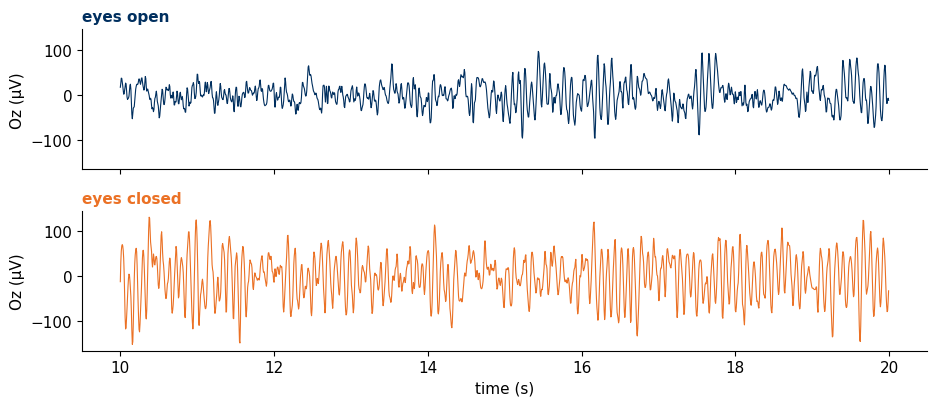

In [5]:
# §1.1 · 10 s of Oz (1-40 Hz), person S007, eyes open (top) and eyes closed (bottom)
need("oz_cont")
i0 = int(10 * SFREQ)                       # from t = 10 s
t = (i0 + np.arange(int(10 * SFREQ))) / SFREQ
fig, axs = plt.subplots(2, 1, figsize=(9.5, 4.2), sharex=True, sharey=True)
for ax, lab, col, name in ((axs[0], 0, EO_C, "eyes open"), (axs[1], 1, EC_C, "eyes closed")):
    ax.plot(t, oz_cont[(7, lab)][i0:i0 + len(t)], color=col, lw=0.8)
    ax.set_ylabel("Oz (µV)")
    ax.set_title(name, loc="left", color=col, fontweight="bold", fontsize=11)
axs[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

**What you should see.** With eyes closed, waxing and waning bursts at about 10 Hz: the **alpha rhythm**. With eyes
open there are smaller, irregular bursts too.

*Why S007?* S007's rise in alpha when the eyes close (3.35×) is the closest to the group median
(3.37×), so S007 was not picked for the biggest effect. Its alpha is strong overall, though: the
highest of the 20 with eyes open and the
4th highest with eyes closed.

**§1.2 · Shuffle the samples: what survives?** Take the first 2 s of that eyes-closed trace (320 samples) and put
the samples in random order.
**Predict:** *which stays the same: (1) the mean, (2) the variance, (3) the alpha power?*

mean (µV), original: 0.012  · lecture run 0.012
mean (µV), shuffled: 0.012  · lecture run 0.012
variance (µV²), original: 3327  · lecture run 3327
variance (µV²), shuffled: 3327  · lecture run 3327
same values, same histogram: True
alpha power (µV²/Hz), original: 401  · lecture run 401
alpha power (µV²/Hz), shuffled: 26  · lecture run 26
all 600 eyes-closed windows, median alpha power shuffled / original: 0.19  · lecture run 0.19
windows whose alpha power falls after shuffling: 582  · lecture run 582


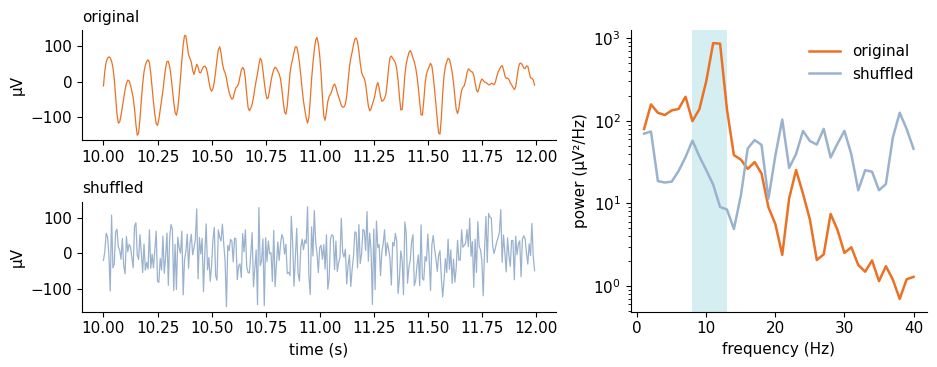

In [6]:
# §1.2 · Shuffle the 320 samples of one 2-s window (S007, eyes closed, Oz, t = 10-12 s)
need("oz_cont")


def alpha_power(x):
    "Mean Welch power (µV²/Hz) in the 8-13 Hz bins, with the settings of the features."
    f_, p_ = welch(x, fs=SFREQ, nperseg=160, noverlap=80, axis=-1)
    return p_[..., (f_ >= ALPHA[0]) & (f_ <= ALPHA[1])].mean(-1)


def oz_windows(lab):
    "All 2-s Oz windows (µV) of one condition, people in order: shape (600, 320)."
    return np.concatenate([oz_cont[(s, lab)][:(len(oz_cont[(s, lab)]) // WIN) * WIN].reshape(-1, WIN)
                           for s in SUBJECTS])


seg = oz_cont[(7, 1)][5 * WIN:6 * WIN]                       # window 5 of the recording = t 10-12 s
shuf = seg[np.random.default_rng(SEED).permutation(WIN)]
show("mean (µV), original", seg.mean(), key="shuffle_s007_ec_oz_mean_uV", nd=3)
show("mean (µV), shuffled", shuf.mean(), key="shuffle_s007_ec_oz_mean_uV_shuffled", nd=3)
show("variance (µV²), original", seg.var(), key="shuffle_s007_ec_oz_var_uV2", nd=0)
show("variance (µV²), shuffled", shuf.var(), key="shuffle_s007_ec_oz_var_uV2_shuffled", nd=0)
print("same values, same histogram:", np.array_equal(np.sort(seg), np.sort(shuf)))
show("alpha power (µV²/Hz), original", alpha_power(seg), key="shuffle_s007_ec_oz_alpha_power_original", nd=0)
show("alpha power (µV²/Hz), shuffled", alpha_power(shuf), key="shuffle_s007_ec_oz_alpha_power_shuffled", nd=0)

W_ec = oz_windows(1)                                         # all 600 eyes-closed windows
rng = np.random.default_rng(SEED)
W_sh = np.stack([w_[rng.permutation(WIN)] for w_ in W_ec])
ratio_sh = alpha_power(W_sh) / alpha_power(W_ec)
show("all 600 eyes-closed windows, median alpha power shuffled / original", np.median(ratio_sh),
     key="shuffle_ec_oz_alpha_power_ratio_shuffled_over_original_median")
show("windows whose alpha power falls after shuffling", (ratio_sh < 1).sum(),
     key="shuffle_ec_oz_n_windows_alpha_power_lower_after_shuffle", nd=0)

ts_ = 10 + np.arange(WIN) / SFREQ
fig = plt.figure(figsize=(9.5, 3.8))
gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1])
a0, a1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
a0.plot(ts_, seg, color=EC_C, lw=0.9); a0.set_ylabel("µV"); a0.set_title("original", fontsize=11, loc="left")
a1.plot(ts_, shuf, color=GREYBLUE, lw=0.9); a1.set_ylabel("µV"); a1.set_xlabel("time (s)")
a1.set_title("shuffled", fontsize=11, loc="left")
a1.set_ylim(a0.get_ylim())
a2 = fig.add_subplot(gs[:, 1])
for x_, col, name in ((seg, EC_C, "original"), (shuf, GREYBLUE, "shuffled")):
    f_, p_ = welch(x_, fs=SFREQ, nperseg=160, noverlap=80)
    k_ = (f_ >= 1) & (f_ <= 40)
    a2.semilogy(f_[k_], p_[k_], color=col, lw=1.8, label=name)
a2.axvspan(*ALPHA, color=LIGHTBLUE, alpha=0.5, lw=0)
a2.set_xlabel("frequency (Hz)"); a2.set_ylabel("power (µV²/Hz)"); a2.legend(frameon=False)
plt.tight_layout(); plt.show()

**What you should see.** The mean (0.012 µV), the variance
(3,327 µV²) and the histogram are identical, but the alpha power falls from
401 to 26 µV²/Hz
(× 0.06): same values, no rhythm. Over all
600 eyes-closed windows the alpha power falls in
582 (median × 0.19).
The information is in the **order** of the samples; time-series methods use it (filters, spectra, convolutions).

**§1.3 · From a trace to a spectrum to band power.** The **power spectrum** says how much of the signal's variance
sits at each frequency. We use Welch's method: average the spectra of 1-s pieces of the window, which gives 1-Hz steps.
A **band** is a named frequency range: delta 1–4, theta 4–8, alpha 8–13, beta 13–30 and gamma 30–40 Hz here (the
edges vary between papers). **Band power** = the average of the spectrum inside a band.

**Predict:** *which band changes most when the eyes close? By the same amount in every person?*

alpha ratio closed / open, median over people: 3.37  · lecture run 3.37
lowest: 1.12  · lecture run 1.12
highest: 21.12  · lecture run 21.12
people with a ratio below 1: 0  · lecture run 0
8-12 Hz occipital power, eyes open (µV²/Hz): 24.9  · lecture run 24.9
8-12 Hz occipital power, eyes closed (µV²/Hz): 158.1  · lecture run 158.1
ratio of the group means (used again in §4): 6.35  · lecture run 6.35


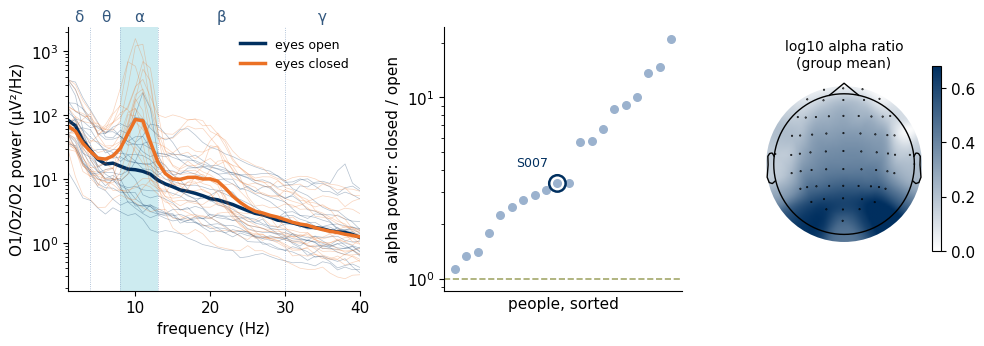

largest alpha ratio at: PO8


In [7]:
# §1.3 · Spectrum of every window (Welch, 1-s pieces, 1-40 Hz), occipital spectra and the alpha ratio per person
need("y")
if X is not None:
    f_all, P_all = welch(X, fs=SFREQ, nperseg=160, noverlap=80, axis=-1)
    keep = (f_all >= 1) & (f_all <= 40)
    freqs = f_all[keep]
    logP = np.log10(P_all[..., keep] * 1e12)                 # (1200, 64, 40) log10 µV²/Hz
    del P_all
else:
    freqs, logP = fb["f"], fb["logP"].astype(np.float64)
P = 10 ** logP                                               # µV²/Hz
occ = [ch_names.index(c) for c in OCC]
front = [ch_names.index(c) for c in FRONT]


def in_band(lo, hi):
    return (freqs >= lo) & (freqs <= hi)


def per_person(v, lab):
    "Mean of a per-window value over each person's windows of one condition."
    return np.array([v[(g == s) & (y == lab)].mean() for s in SUBJECTS])


occ_alpha = P[:, occ][:, :, in_band(*ALPHA)].mean(axis=(1, 2))     # µV²/Hz per window
a_eo, a_ec = per_person(occ_alpha, 0), per_person(occ_alpha, 1)
ratio = a_ec / a_eo
show("alpha ratio closed / open, median over people", np.median(ratio), key="alpha_ratio_median")
show("lowest", ratio.min(), key="alpha_ratio_min")
show("highest", ratio.max(), key="alpha_ratio_max")
show("people with a ratio below 1", (ratio < 1).sum(), key="alpha_ratio_n_below_1", nd=0)
occ_a812 = P[:, occ][:, :, in_band(*ALPHA_ENV)].mean(axis=(1, 2))
m_eo, m_ec = per_person(occ_a812, 0).mean(), per_person(occ_a812, 1).mean()
show("8-12 Hz occipital power, eyes open (µV²/Hz)", m_eo, key="graph_occipital_alpha_8_12_power_uV2perHz_eyes_open", nd=1)
show("8-12 Hz occipital power, eyes closed (µV²/Hz)", m_ec, key="graph_occipital_alpha_8_12_power_uV2perHz_eyes_closed", nd=1)
show("ratio of the group means (used again in §4)", m_ec / m_eo,
     key="graph_occipital_alpha_8_12_power_ratio_EC_over_EO_of_group_means")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.35, 1.1, 0.9]})
ax = axs[0]
ax.axvspan(*BANDS["alpha"], color=LIGHTBLUE, alpha=0.6, lw=0)               # the alpha band shaded
for (name, (lo, hi)), greek in zip(BANDS.items(), "δθαβγ"):
    ax.axvline(hi, color=GREYBLUE, lw=0.6, ls=":")
    ax.text((lo + hi) / 2, 1.02, greek, transform=ax.get_xaxis_transform(), ha="center", fontsize=11, color=STEEL)
for lab, col in ((0, EO_C), (1, EC_C)):
    pp = np.array([np.log10(P[(g == s) & (y == lab)][:, occ].mean(axis=(0, 1))) for s in SUBJECTS])
    for row in pp:
        ax.plot(freqs, 10 ** row, color=col, lw=0.5, alpha=0.3)
    ax.plot(freqs, 10 ** pp.mean(0), color=col, lw=2.5, label=["eyes open", "eyes closed"][lab])
ax.set_yscale("log"); ax.set_xlim(1, 40)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("O1/Oz/O2 power (µV²/Hz)"); ax.legend(frameon=False, fontsize=9)
ax = axs[1]
order = np.argsort(ratio)
ax.scatter(np.arange(len(ratio)), ratio[order], color=GREYBLUE, s=30, zorder=3)
k7 = int(np.flatnonzero(np.array(SUBJECTS)[order] == 7)[0])
ax.scatter([k7], [ratio[order][k7]], s=140, facecolors="none", edgecolors=NAVY, lw=1.8, zorder=4)
ax.annotate("S007", (k7, ratio[order][k7]), xytext=(-30, 12), textcoords="offset points", color=NAVY, fontsize=9)
ax.axhline(1, color=OLIVE, ls="--", lw=1.2)
ax.set_yscale("log"); ax.set_xticks([]); ax.set_xlabel("people, sorted")
ax.set_ylabel("alpha power: closed / open")
ax = axs[2]
info = mne.create_info(ch_names, SFREQ, "eeg"); info.set_montage("standard_1005")
ratio_ch = np.mean([np.log10(P[(g == s) & (y == 1)][:, :, in_band(*ALPHA)].mean(axis=(0, 2))
                             / P[(g == s) & (y == 0)][:, :, in_band(*ALPHA)].mean(axis=(0, 2))) for s in SUBJECTS], axis=0)
im, _ = mne.viz.plot_topomap(ratio_ch, info, axes=ax, show=False, cmap=WHITE_NAVY, contours=0)
ax.set_title("log10 alpha ratio\n(group mean)", fontsize=10)
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()
print("largest alpha ratio at:", ch_names[int(np.argmax(ratio_ch))])

**What you should see.** With eyes closed the spectrum has a peak at 8–13 Hz (alpha). Everyone's alpha goes up — the
ratio is above 1 in all 20 people (median 3.37×) — but by 1.12× in one person
and 21.12× in another. Averaged over people, occipital alpha (8–12 Hz) rises from
24.9 to 158.1
µV²/Hz, about 6× (we use this again in §4).
The map shows the rise is largest over the back of the head. **People differ more than conditions**: we meet this
again in §2 and §3.

**§1.4 · What a filter does** *(optional — skip in class)*. A **filter** is a weighted moving average that keeps some
frequencies and removes others. Our 1–40 Hz band-pass removes slow drift and the 60-Hz mains hum (US data; it would be
50 Hz in Argentina). An 8–13 Hz band-pass isolates alpha; the **envelope** (the amplitude from the Hilbert transform)
of the 8–12 Hz signal follows how strong alpha is from moment to moment (§4). Our filter is **zero-phase**: it does not
shift the signal in time, because each output sample uses ±1.65 s of past *and future* input. That is right for
describing a recording; a device that must react in real time (a brain–computer interface) can only use the past.

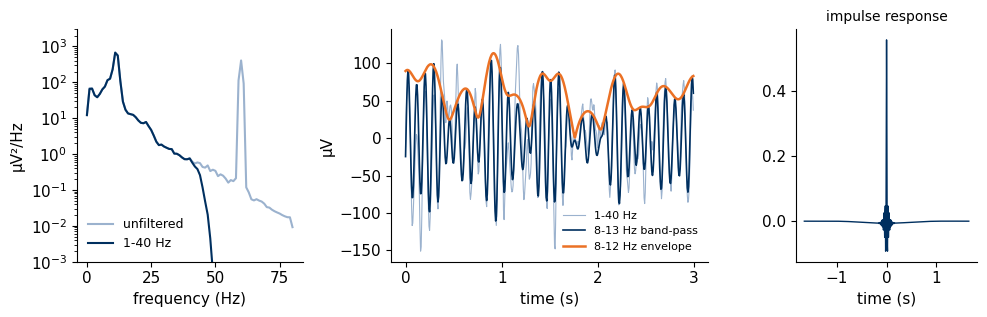

S007, unfiltered Oz: the 60-Hz bin is 3.65 log10 units above the mean of 55 and 65 Hz
filter length (samples): 529  · lecture run 529


In [8]:
# §1.4 · (optional) Unfiltered vs filtered spectrum, band-pass + envelope, and the filter's impulse response
need("oz_unf")
x_unf = oz_unf[(7, 1)]                                       # S007, eyes closed, Oz, µV
x_140 = mne.filter.filter_data(x_unf * 1e-6, SFREQ, 1.0, 40.0, fir_design="firwin") * 1e6
x_alpha = mne.filter.filter_data(x_140 * 1e-6, SFREQ, 8.0, 13.0, fir_design="firwin") * 1e6
x_812 = mne.filter.filter_data(x_140 * 1e-6, SFREQ, 8.0, 12.0, fir_design="firwin") * 1e6
env = np.abs(hilbert(x_812, N=next_fast_len(len(x_812)))[:len(x_812)])
fig, axs = plt.subplots(1, 3, figsize=(10, 3.3), gridspec_kw={"width_ratios": [1, 1.4, 0.8]})
for x_, col, name in ((x_unf, GREYBLUE, "unfiltered"), (x_140, NAVY, "1-40 Hz")):
    f_, p_ = welch(x_, fs=SFREQ, nperseg=160, noverlap=80)
    axs[0].semilogy(f_, p_, color=col, lw=1.5, label=name)
axs[0].set_ylim(1e-3, 3e3)
axs[0].set_xlabel("frequency (Hz)"); axs[0].set_ylabel("µV²/Hz"); axs[0].legend(frameon=False, fontsize=9)
f_, p_ = welch(x_unf, fs=SFREQ, nperseg=160, noverlap=80)
peak60 = np.log10(p_[f_ == 60][0]) - np.log10(p_[(f_ == 55) | (f_ == 65)]).mean()
tt = np.arange(3 * int(SFREQ)) / SFREQ
k0 = int(10 * SFREQ)
axs[1].plot(tt, x_140[k0:k0 + len(tt)], color=GREYBLUE, lw=0.8, label="1-40 Hz")
axs[1].plot(tt, x_alpha[k0:k0 + len(tt)], color=NAVY, lw=1.2, label="8-13 Hz band-pass")
axs[1].plot(tt, env[k0:k0 + len(tt)], color=ORANGE, lw=1.8, label="8-12 Hz envelope")
axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("µV"); axs[1].legend(frameon=False, fontsize=8, loc="lower right")
h = mne.filter.create_filter(None, SFREQ, 1.0, 40.0, fir_design="firwin")
axs[2].plot((np.arange(len(h)) - len(h) // 2) / SFREQ, h, color=NAVY, lw=1)
axs[2].set_xlabel("time (s)"); axs[2].set_title("impulse response", fontsize=10)
plt.tight_layout(); plt.show()
print(f"S007, unfiltered Oz: the 60-Hz bin is {peak60:.2f} log10 units above the mean of 55 and 65 Hz")
show("filter length (samples)", len(h), key="preproc_fir_length_samples", nd=0)

**What you should see.** A sharp peak at 60 Hz in the unfiltered spectrum that the filter removes (over all
recordings it stands 1.13 log10 units, about
14×, above its neighbours). The envelope rises and
falls with the alpha bursts. The impulse response is symmetric around 0: the filter uses
529 samples = 3.3 s, half of them from the future.

## §2 · PREDICT: eyes open or closed, tested on new people

**§2.1 · Features: from 20,480 numbers to a spectrum per channel.**
- A **feature** is a number that describes a window; the **label** is the answer we want (open or closed).
- A **model** is a function learned from labelled examples; its adjustable numbers are its **parameters**. Here:
  logistic regression, which weighs the features and outputs a probability (Part 2 of the lecture).
- **Training / test:** learn on some windows, judge on others the model has never seen. **Cross-validation:** repeat
  that 5 times with a different test set each time, and average. *0.75 means 75% of test windows correct.*

We use the spectra of §1.3 as features: one feature (mean occipital alpha) or the full spectrum (64 channels × 40
frequencies). This is **featurization**: we decide, from prior knowledge, how to turn each window into features and
give them to a traditional model; the other route, **deep learning** on the raw window, learns its own features (more
data needed, less bias; ROCKET sits halfway; Part 3 of the lecture).

In [9]:
# §2.1 · Two feature sets from the spectra of §1.3
need("logP")
F_one = logP[:, occ][:, :, in_band(*ALPHA)].mean(axis=(1, 2))[:, None]   # 1 feature: mean log alpha power, O1/Oz/O2
F_full = logP.reshape(len(y), -1)                                         # 64 channels x 40 frequencies
print("F_one", F_one.shape, "| F_full", F_full.shape)

F_one (1200, 1) | F_full (1200, 2560)


**What you should see.** `F_one (1200, 1)` and `F_full (1200, 2,560)`: each
window goes from 20,480 raw numbers to 1 or 2,560
features.

**§2.2 · A baseline, one feature, the full spectrum — on people the model has never seen.** Each round of the
cross-validation holds out 4 whole people (`GroupKFold`, groups = person). A model that always answers the most common
label is our **baseline**.

**Predict:** *What will the baseline score? Will 2,560 features beat 1 alpha feature? Will the model score higher on
the windows it trained on than on new people?* (Trust check **BASELINE**.)

baseline (always the most common label): 0.50 ± 0.00 (50%)  · lecture run 0.50 ± 0.00
1 feature (occipital alpha): 0.64 ± 0.08 (64%)  · lecture run 0.64 ± 0.08
full spectrum (2,560 features): 0.75 ± 0.12 (75%)  · lecture run 0.75 ± 0.12
   folds: [0.8  0.74 0.75 0.9  0.54] · lecture run [0.8042, 0.7375, 0.7542, 0.9, 0.5417]
full spectrum, on its own training windows: 1.00 (100%)  · lecture run 1.00
per held-out person: lowest: 0.50  · lecture run 0.50
per held-out person: median: 0.73  · lecture run 0.73
per held-out person: highest: 1.00  · lecture run 1.00


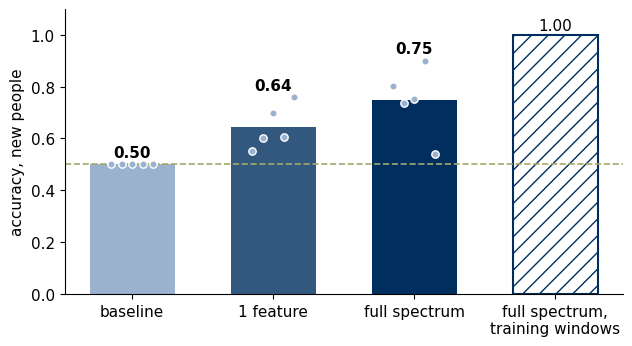

In [10]:
# §2.2 · Baseline, one feature and the full spectrum, person-grouped cross-validation
need("F_full")
acc_base = cv_acc(F_full, clf=DummyClassifier(strategy="most_frequent"))
acc_one = cv_acc(F_one)
res_full = cross_validate(make_clf(), F_full, y, groups=g, cv=CV_PERSON, return_train_score=True)
acc_full, acc_full_train = res_full["test_score"], res_full["train_score"]
pred_full = cross_val_predict(make_clf(), F_full, y, groups=g, cv=CV_PERSON)
acc_person = np.array([(pred_full[g == s] == y[g == s]).mean() for s in SUBJECTS])

show_cv("baseline (always the most common label)", acc_base, prefix="clf_dummy_most_frequent_honest")
show_cv("1 feature (occipital alpha)", acc_one, prefix="clf_one_feature_occipital_alpha_mean_logpower_honest")
show_cv("full spectrum (2,560 features)", acc_full, prefix="clf_full_logpsd_64x40_honest")
print("   folds:", np.round(acc_full, 2), "· lecture run", EXPECTED["clf_full_logpsd_64x40_honest_folds"])
show("full spectrum, on its own training windows", acc_full_train.mean(), key="overfit_logpsd_C1_train_acc_mean", pct=True)
show("per held-out person: lowest", acc_person.min(), key="clf_full_logpsd_64x40_honest_per_subject_acc_min")
show("per held-out person: median", np.median(acc_person), key="clf_full_logpsd_64x40_honest_per_subject_acc_median")
show("per held-out person: highest", acc_person.max(), key="clf_full_logpsd_64x40_honest_per_subject_acc_max")
note("classify", acc_base.mean(), acc_one.mean(), acc_full.mean())
note("train_test", acc_full_train.mean(), acc_full.mean())
note("per_person", acc_person.min(), acc_person.max(), np.median(acc_person))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, (sc, col, name) in enumerate(((acc_base, GREYBLUE, "baseline"), (acc_one, STEEL, "1 feature"),
                                     (acc_full, NAVY, "full spectrum"))):
    ax.bar(k, sc.mean(), color=col, width=0.6)
    ax.scatter(np.full(5, k) + np.linspace(-0.15, 0.15, 5), sc, color=GREYBLUE, edgecolor="white", s=28, zorder=3)
    ax.text(k, max(sc.max(), sc.mean()) + 0.03, f"{sc.mean():.2f}", ha="center", fontweight="bold")
ax.bar(3, acc_full_train.mean(), width=0.6, facecolor="none", edgecolor=NAVY, lw=1.5, hatch="//")
ax.text(3, acc_full_train.mean() + 0.02, f"{acc_full_train.mean():.2f}", ha="center")
ax.axhline(0.5, color=OLIVE, ls="--", lw=1.2)
ax.set_xticks(range(4), ["baseline", "1 feature", "full spectrum", "full spectrum,\ntraining windows"])
ax.set_ylim(0, 1.1); ax.set_ylabel("accuracy, new people")
plt.tight_layout(); plt.show()

**What you should see.** Baseline 0.50; one feature
0.64 ± 0.08;
full spectrum 0.75 ± 0.12
(10
points better). On its own training windows the same model scores 1.00: learning is
not memorizing, only the test score counts. The folds spread from 0.54 to
0.90 and single people from 0.50
to 1.00: the result depends on *which* people are tested
(trust check **UNCERTAINTY**).

**§2.3 · Inside the one-feature model: p = σ(w·x + b).** The model computes a weighted sum *z = w·x + b* of the
(z-scored) alpha feature x, squashes it with the sigmoid σ(z) = 1 / (1 + e^(−z)) into a probability of "eyes closed",
and answers "closed" when p > 0.5. Its **parameters** are w and b. scikit-learn chose them by lowering the **loss**
(cross-entropy: how wrong the probabilities are on the training windows), with a small penalty on large weights
(**regularization**, `C = 1`). §B6 does the same by hand, step by step (gradient descent).

**Predict:** *where will the model put its decision point, in µV²/Hz of alpha power?*

weight w: 0.97  · lecture run 0.97
offset b: 0.01  · lecture run 0.01
decision point (µV²/Hz of alpha power): 17.5  · lecture run 17.5
accuracy on these same windows: 0.65 (65%)  · lecture run 0.65
eyes-open windows above the decision point: 211  · lecture run 211
eyes-closed windows below it: 211  · lecture run 211


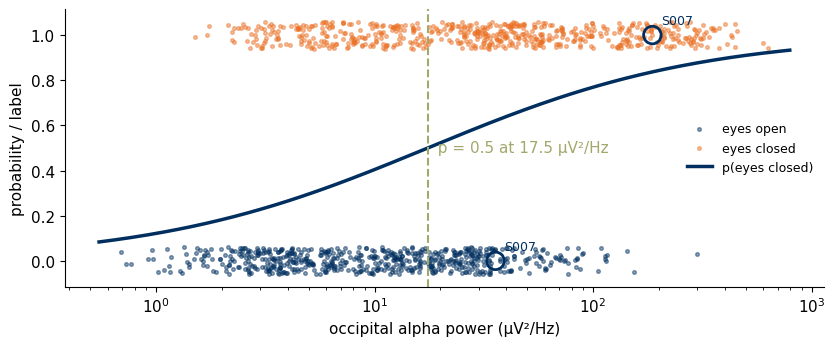

In [11]:
# §2.3 · Fit the one-feature model on all 1,200 windows (a description of the fit; the honest score stays the one of §2.2)
need("F_one")
m1 = make_clf().fit(F_one, y)
w1, b1 = m1.named_steps["lr"].coef_[0, 0], m1.named_steps["lr"].intercept_[0]
mu1, sd1 = m1.named_steps["scale"].mean_[0], m1.named_steps["scale"].scale_[0]
thr_log = mu1 + sd1 * (-b1 / w1)                       # p = 0.5 where w z + b = 0, back in log10 µV²/Hz
show("weight w", w1, key="lr1_sklearn_C1_lecture_protocol_w")
show("offset b", b1, key="lr1_sklearn_C1_lecture_protocol_b")
show("decision point (µV²/Hz of alpha power)", 10 ** thr_log, key="lr1_threshold_uV2perHz", nd=1)
show("accuracy on these same windows", m1.score(F_one, y), key="lr1_train_acc", pct=True)
show("eyes-open windows above the decision point", (F_one[y == 0, 0] > thr_log).sum(),
     key="lr1_n_windows_above_threshold_eyes_open", nd=0)
show("eyes-closed windows below it", (F_one[y == 1, 0] <= thr_log).sum(),
     key="lr1_n_windows_below_threshold_eyes_closed", nd=0)

rng = np.random.default_rng(SEED)
xs = np.linspace(F_one.min() - 0.1, F_one.max() + 0.1, 300)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for lab, col, name in ((0, EO_C, "eyes open"), (1, EC_C, "eyes closed")):
    xv = F_one[y == lab, 0]
    ax.scatter(10 ** xv, lab + rng.uniform(-0.06, 0.06, len(xv)), s=7, color=col, alpha=0.45, label=name)
ax.plot(10 ** xs, m1.predict_proba(xs[:, None])[:, 1], color=NAVY, lw=2.5, label="p(eyes closed)")
ax.axvline(10 ** thr_log, color=OLIVE, ls="--", lw=1.5)
ax.text(10 ** thr_log, 0.5, f"  p = 0.5 at {10 ** thr_log:.1f} µV²/Hz", color=OLIVE, va="center")
for lab in (0, 1):
    xm = F_one[(g == 7) & (y == lab), 0].mean()
    ax.scatter([10 ** xm], [lab], s=160, facecolors="none", edgecolors=NAVY, lw=2, zorder=4)
    ax.annotate("S007", (10 ** xm, lab), xytext=(6, 8), textcoords="offset points", color=NAVY, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("occipital alpha power (µV²/Hz)"); ax.set_ylabel("probability / label")
ax.legend(frameon=False, fontsize=9, loc="center right")
plt.tight_layout(); plt.show()

**What you should see.** One weight (w ≈ 0.97), one offset
(b ≈ 0.01) and an S-shaped curve: that is the whole model. It answers "closed"
above about 17.5 µV²/Hz of alpha power. 211
eyes-open windows sit above that point (people with strong alpha, S007 among them) and
211 eyes-closed windows below it, which is why one feature reaches only
0.65 even on its own training windows and 0.64
on new people. (The slides' cut-off on the 40 person means, 43 µV²/Hz, was set on
different numbers — person averages, not windows — so the two need not match.)

**§2.4 · Predict, then run: shuffle the windows instead of the people.** Same model, same 2,560 features. Now we
shuffle all 1,200 windows and split them 5 ways, so windows of the *same person* land in both training and test.

**Say your guess before you run.** *Higher, lower or the same as 0.75?*

full spectrum, shuffled windows: 0.91 ± 0.02 (91%)  · lecture run 0.91 ± 0.02
gain over the person split (points): 16.4  · lecture run 16.4
baseline under the shuffled split: 0.48  · lecture run 0.48


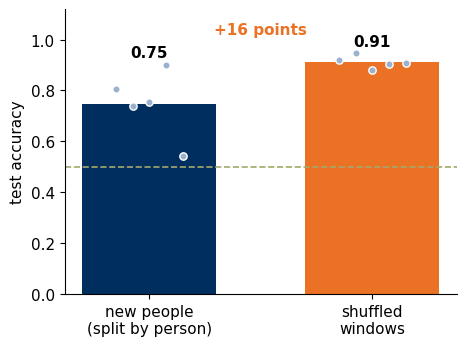

In [12]:
# §2.4 · Same model, but the 5 folds are made of shuffled windows (people appear in training and test)
need("acc_full")
acc_leaky = cv_acc(F_full, cv=CV_SHUFFLED)
acc_base_leaky = cv_acc(F_full, cv=CV_SHUFFLED, clf=DummyClassifier(strategy="most_frequent"))
show_cv("full spectrum, shuffled windows", acc_leaky, prefix="clf_full_logpsd_64x40_leaky")
show("gain over the person split (points)", 100 * (acc_leaky.mean() - acc_full.mean()),
     key="clf_leak_gain_full_logpsd_points", nd=1)
show("baseline under the shuffled split", acc_base_leaky.mean(), key="clf_dummy_most_frequent_leaky_mean")
note("shuffled", acc_leaky.mean(), 100 * (acc_leaky.mean() - acc_full.mean()))

fig, ax = plt.subplots(figsize=(4.8, 3.6))
for k, (sc, col) in enumerate(((acc_full, NAVY), (acc_leaky, ORANGE))):
    ax.bar(k, sc.mean(), color=col, width=0.6)
    ax.scatter(np.full(5, k) + np.linspace(-0.15, 0.15, 5), sc, color=GREYBLUE, edgecolor="white", s=28, zorder=3)
    ax.text(k, max(sc.max(), sc.mean()) + 0.03, f"{sc.mean():.2f}", ha="center", fontweight="bold")
ax.text(0.5, 1.02, f"+{100 * (acc_leaky.mean() - acc_full.mean()):.0f} points", ha="center", color=ORANGE,
        fontweight="bold")
ax.axhline(0.5, color=OLIVE, ls="--", lw=1.2)
ax.set_xticks([0, 1], ["new people\n(split by person)", "shuffled\nwindows"]); ax.set_ylim(0, 1.12)
ax.set_ylabel("test accuracy")
plt.tight_layout(); plt.show()

**What you should see.** About 0.91 ± 0.02:
+16 points, without learning anything new about eyes (the baseline stays near
0.48). The model recognises the *person* — each person's spectrum is a fingerprint —
and has already seen that person's other windows.

**Trust check · SPLIT:** test on the unit you want to generalise to — here, a new person.

**§2.5 · How sure are we? A 95% interval over people** *(optional — skip in class)*. We resample the 20 people with
replacement 2,000 times and recompute the mean accuracy each time (a **bootstrap**).

95% interval over people: 0.67-0.83  · lecture run 0.67-0.83


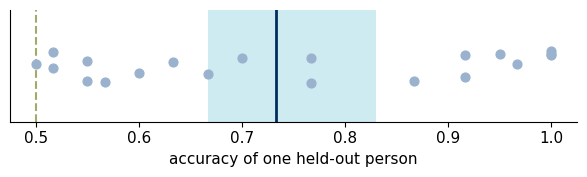

In [13]:
# §2.5 · (optional) Bootstrap over people of the per-person accuracies of §2.2
need("acc_full")
rng = np.random.default_rng(SEED)
n_people = len(acc_person)
boots = np.array([acc_person[rng.integers(0, n_people, n_people)].mean() for _ in range(2000)])
ci = np.percentile(boots, [2.5, 97.5])
print(f"95% interval over people: {ci[0]:.2f}-{ci[1]:.2f}  · lecture run "
      f"{EXPECTED['clf_full_logpsd_64x40_honest_subject_bootstrap95ci'][0]:.2f}-"
      f"{EXPECTED['clf_full_logpsd_64x40_honest_subject_bootstrap95ci'][1]:.2f}")
CHECK["clf_full_logpsd_64x40_honest_subject_bootstrap95ci"] = [float(c) for c in ci]
fig, ax = plt.subplots(figsize=(6, 1.9))
ax.scatter(acc_person, np.random.default_rng(SEED).uniform(-0.15, 0.15, n_people), color=GREYBLUE, s=40, zorder=3)
ax.axvline(np.median(acc_person), color=NAVY, lw=2); ax.axvspan(*ci, color=LIGHTBLUE, alpha=0.6, lw=0)
ax.axvline(0.5, color=OLIVE, ls="--"); ax.set_yticks([]); ax.set_xlabel("accuracy of one held-out person")
ax.set_ylim(-0.5, 0.5); plt.tight_layout(); plt.show()

**Trust check · UNCERTAINTY:** with 20 people, one number hides a wide range.

**§2.6 · What §2 showed.**
- Q1 so far: yes — for new people about 3 times in 4 (0.75), but anywhere from
  0.50 to 1.00
  depending on the person.
- Changing the *evaluation* moved the score more (+16 points) than changing
  the *features* did.
- Next: why the person matters so much (§3).

## §3 · REPRESENT (embed or cluster): a map and clusters of the 1,200 windows

**§3.1 · A map: what organises the cloud?**
- A **representation** is the set of numbers we use to describe each example; REPRESENT means finding a better one.
  An **embedding** squeezes each window (2,560 numbers) into a few (here 2), so that similar windows land close
  together.
- **PCA** keeps the directions of largest variance (straight axes). **t-SNE** keeps neighbourhoods; the distances
  between islands mean little.
- **Silhouette** measures how tight and separate groups are (1 = tight and separate; 0 = no grouping).

**Predict:** *coloured by eyes, will you see two islands? If not, what else could make the islands?*

t-SNE silhouette by person: 0.32  · lecture run 0.32
t-SNE silhouette by eyes: 0.05  · lecture run 0.05
PCA silhouette by person: 0.007  · lecture run 0.007
PCA silhouette by eyes: 0.059  · lecture run 0.059
variance explained: PC1 0.500, PC2 0.075  · lecture run [0.5, 0.075]
(t-SNE numbers can differ by about ±0.03 across library versions or computers)


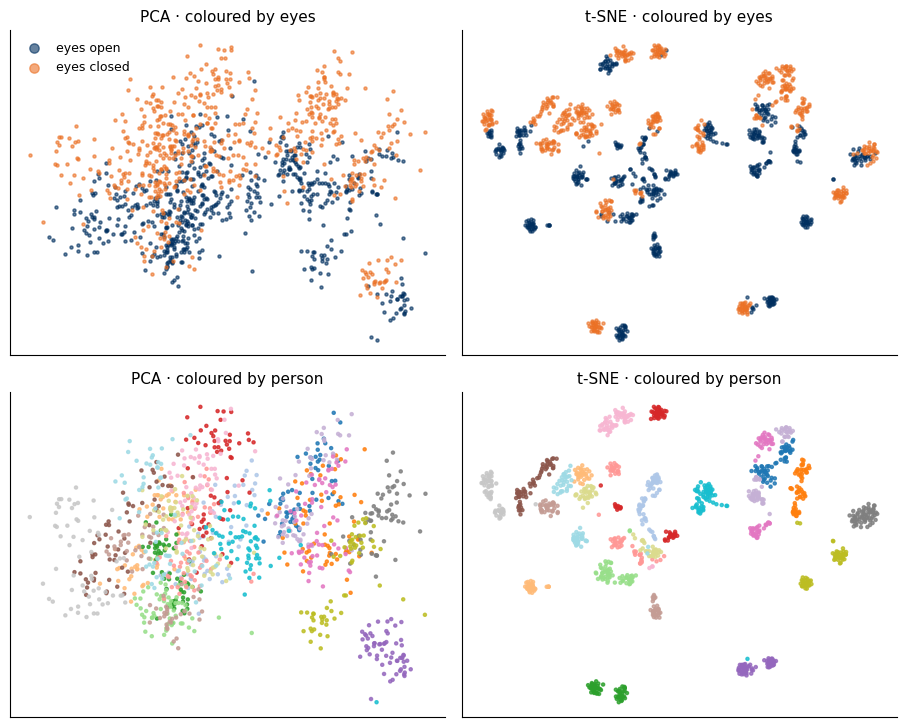

In [14]:
# §3.1 · PCA and t-SNE of the 2,560-number spectra (no labels used), coloured by eyes and by person
need("F_full")
Fs = StandardScaler().fit_transform(F_full)
pca2 = PCA(n_components=2, random_state=SEED).fit(Fs)
Z_pca = pca2.transform(Fs)
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Fs)
sil = {(m, by): silhouette_score(Z, lab) for m, Z in (("pca", Z_pca), ("tsne", Z_tsne)) for by, lab in (("person", g), ("eyes", y))}
show("t-SNE silhouette by person", sil[("tsne", "person")], key="embed_raw_tsne_silhouette_by_subject")
show("t-SNE silhouette by eyes", sil[("tsne", "eyes")], key="embed_raw_tsne_silhouette_by_condition")
show("PCA silhouette by person", sil[("pca", "person")], key="embed_raw_pca_silhouette_by_subject", nd=3)
show("PCA silhouette by eyes", sil[("pca", "eyes")], key="embed_raw_pca_silhouette_by_condition", nd=3)
print(f"variance explained: PC1 {pca2.explained_variance_ratio_[0]:.3f}, PC2 {pca2.explained_variance_ratio_[1]:.3f}"
      f"  · lecture run {EXPECTED['embed_raw_pca_explained_variance_pc1_pc2']}")
CHECK["embed_raw_pca_explained_variance_pc1_pc2"] = [float(v) for v in pca2.explained_variance_ratio_]
print("(t-SNE numbers can differ by about ±0.03 across library versions or computers)")


def map_panels(Z_list, titles):
    fig, axs = plt.subplots(2, len(Z_list), figsize=(4.6 * len(Z_list), 7.4))
    axs = np.atleast_2d(axs).reshape(2, len(Z_list))
    for j, (Z, ttl) in enumerate(zip(Z_list, titles)):
        for lab, col, name in ((0, EO_C, "eyes open"), (1, EC_C, "eyes closed")):
            axs[0, j].scatter(*Z[y == lab].T, s=5, color=col, alpha=0.6, label=name)
        axs[1, j].scatter(*Z.T, s=5, c=g, cmap="tab20", alpha=0.8)
        axs[0, j].set_title(f"{ttl} · coloured by eyes", fontsize=11)
        axs[1, j].set_title(f"{ttl} · coloured by person", fontsize=11)
        for ax in axs[:, j]:
            ax.set_xticks([]); ax.set_yticks([])
    axs[0, 0].legend(frameon=False, markerscale=3, fontsize=9)
    plt.tight_layout(); plt.show()


map_panels([Z_pca, Z_tsne], ["PCA", "t-SNE"])

**What you should see.** Coloured by person, the t-SNE map falls into islands (silhouette by person
0.32); coloured by eyes, the two colours are mixed inside every island
(silhouette 0.05). PC1 alone explains
50% of the variance. **The islands are people.**

**Trust check · SPLIT:** this is why the shuffled split of §2.4 looked so good — the person is the biggest source of
variation, so a shuffled split tests on people the model has already seen.

**§3.2 · Clustering compresses each window to one of k prototypes.**
- **Clustering** groups examples *without* labels. It is a way of compressing the data: each window is replaced by
  the number of its group, i.e. by one of k **prototypes**.
- **k-means:** place k centres, assign each window to the nearest one, move each centre to the middle of its windows,
  repeat. Its goal is the smallest total squared distance from the windows to their centres.
- **ARI** (adjusted Rand index) compares two groupings: 0 = no better than chance (it can be slightly negative),
  1 = identical.

**Predict:** *with k = 2, will k-means split the windows into eyes open and eyes closed?*

k = 2 · ARI with eyes: 0.00  · lecture run 0.00
k = 2 · ARI with person: 0.08  · lecture run 0.08
k = 20 · ARI with eyes: 0.05  · lecture run 0.05
k = 20 · ARI with person: 0.49  · lecture run 0.49
k = 2 · share of eyes-closed windows in each cluster: 50% and 49%
k = 2 · people with at least 90% of their windows in one cluster: 19  · lecture run 19


,ARI with eyes,ARI with person
k = 2,0.00,0.08
k = 20,0.05,0.49


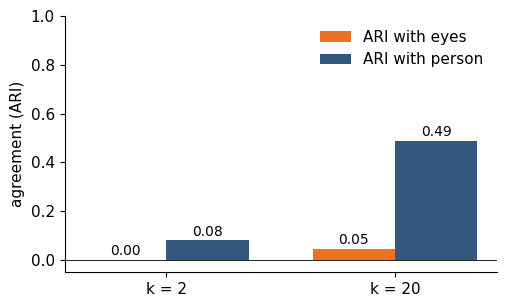

In [15]:
# §3.2 · k-means with k = 2 and k = 20 on the z-scored spectra; compare the clusters with eyes and with people
need("F_full")
Fk = StandardScaler().fit_transform(F_full)
km = {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Fk) for k in (2, 20)}
ari = {(k, by): adjusted_rand_score(lab, km[k]) for k in (2, 20) for by, lab in (("eyes", y), ("person", g))}
show("k = 2 · ARI with eyes", ari[(2, "eyes")], key="cluster_kmeans_raw_k2_ari_eyes")
show("k = 2 · ARI with person", ari[(2, "person")], key="cluster_kmeans_raw_k2_ari_person")
show("k = 20 · ARI with eyes", ari[(20, "eyes")], key="cluster_kmeans_raw_k20_ari_eyes")
show("k = 20 · ARI with person", ari[(20, "person")], key="cluster_kmeans_raw_k20_ari_person")
share = [(y[km[2] == c] == 1).mean() for c in (0, 1)]
print(f"k = 2 · share of eyes-closed windows in each cluster: {share[0]:.0%} and {share[1]:.0%}")
n90 = sum(np.bincount(km[2][g == s], minlength=2).max() / (g == s).sum() >= 0.9 for s in SUBJECTS)
show("k = 2 · people with at least 90% of their windows in one cluster", n90,
     key="cluster_kmeans_raw_k2_n_people_ge90pct_windows_in_one_cluster", nd=0)
if globals().get("sil") is not None:                     # the map of §3.1 gives the first two numbers
    note("represent", sil[("tsne", "person")], sil[("tsne", "eyes")], ari[(2, "eyes")])
display(pd.DataFrame({"ARI with eyes": [ari[(2, "eyes")], ari[(20, "eyes")]],
                      "ARI with person": [ari[(2, "person")], ari[(20, "person")]]},
                     index=["k = 2", "k = 20"]).map(num))
fig, ax = plt.subplots(figsize=(5.2, 3.2))
xk = np.arange(2)
ax.bar(xk - 0.18, [ari[(2, "eyes")], ari[(20, "eyes")]], width=0.36, color=ORANGE, label="ARI with eyes")
ax.bar(xk + 0.18, [ari[(2, "person")], ari[(20, "person")]], width=0.36, color=STEEL, label="ARI with person")
for k_, kk in enumerate((2, 20)):
    for dx, by in ((-0.18, "eyes"), (0.18, "person")):
        ax.text(k_ + dx, max(ari[(kk, by)], 0) + 0.02, num(ari[(kk, by)]), ha="center", fontsize=10)
ax.set_xticks(xk, ["k = 2", "k = 20"]); ax.set_ylim(-0.05, 1); ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("agreement (ARI)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What you should see.** Asked for 2 groups, k-means ignores the eyes (ARI with eyes 0.00;
both clusters are about half eyes closed: 50% and 49%)
and splits the *people*: 19 of 20 people have at least
90% of their windows in one cluster. Asked for 20 groups, it roughly finds the people (ARI with person
0.49, with eyes 0.05).

Clustering is useful when the biggest structure *is* what you care about: on 30-s sleep epochs, k-means partly
matches the expert sleep stages (ARI 0.26; §B3; Decat et al. 2022). Spike sorting is clustering of spike
waveforms (Part 5 of the lecture).

**§3.3 · A better representation: remove each person's average, then map, cluster and classify again.** People differ
so much (§1.3) that we subtract each person's own average first: we z-score each person with all of their windows.

**Predict:** *will the islands now follow the eyes? Will k-means with k = 2 find them? And the classifier on new
people?*

t-SNE silhouette by eyes: 0.33  · lecture run 0.33
t-SNE silhouette by person: −0.12  · lecture run −0.12


k-means, k = 2 · ARI with eyes: 0.51  · lecture run 0.51
k-means, k = 2 · ARI with person: 0.00  · lecture run 0.00
share of eyes-closed windows per cluster: 90%, 18%


classifier on new people, 1 feature: 0.83 ± 0.07 (83%)  · lecture run 0.83 ± 0.07
classifier on new people, full spectrum: 0.92 ± 0.04 (92%)  · lecture run 0.92 ± 0.04


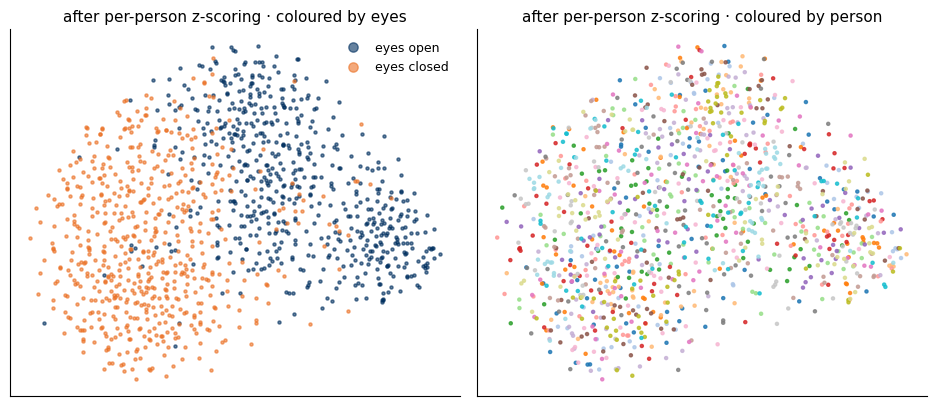

In [16]:
# §3.3 · Per-person z-scoring, then t-SNE, k-means (k = 2) and the classifier on new people
need("F_full")
Fz = subject_z(F_full)
Fzs = StandardScaler().fit_transform(Fz)
Z_tsne_z = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Fzs)
show("t-SNE silhouette by eyes", silhouette_score(Z_tsne_z, y), key="embed_subjectz_tsne_silhouette_by_condition")
show("t-SNE silhouette by person", silhouette_score(Z_tsne_z, g), key="embed_subjectz_tsne_silhouette_by_subject")
km_z = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit_predict(Fzs)
show("k-means, k = 2 · ARI with eyes", adjusted_rand_score(y, km_z), key="cluster_kmeans_subjectz_k2_ari_eyes")
show("k-means, k = 2 · ARI with person", adjusted_rand_score(g, km_z), key="cluster_kmeans_subjectz_k2_ari_person")
print("share of eyes-closed windows per cluster:", ", ".join(f"{(y[km_z == c] == 1).mean():.0%}" for c in (0, 1)))
acc_one_z = cv_acc(subject_z(F_one))
acc_full_z = cv_acc(Fz)
show_cv("classifier on new people, 1 feature", acc_one_z,
        prefix="clf_one_feature_occipital_alpha_mean_logpower_subjectz_honest")
show_cv("classifier on new people, full spectrum", acc_full_z, prefix="clf_full_logpsd_64x40_subjectz_honest")
note("subject_z", adjusted_rand_score(y, km_z), acc_full_z.mean())
fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.2))
for lab, col, name in ((0, EO_C, "eyes open"), (1, EC_C, "eyes closed")):
    axs[0].scatter(*Z_tsne_z[y == lab].T, s=5, color=col, alpha=0.6, label=name)
axs[1].scatter(*Z_tsne_z.T, s=5, c=g, cmap="tab20", alpha=0.8)
axs[0].set_title("after per-person z-scoring · coloured by eyes", fontsize=11)
axs[1].set_title("after per-person z-scoring · coloured by person", fontsize=11)
axs[0].legend(frameon=False, markerscale=3, fontsize=9)
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**What you should see.** Now the map follows the eyes (silhouette by eyes 0.33,
by person −0.12); k-means with k = 2 finds them (ARI
0.51; clusters 90%
and 18% eyes closed); the classifier
reaches 0.83 with 1 feature and
0.92 with the full spectrum on new people.

**The catch.** It works because it uses the new person's windows of *both* conditions to set their zero, so it already
knows that half of them are open and half closed (a "transductive" step). For a single new patient with one recording
this is impossible; it is honest only if every new person first gives a calibration recording of both states (what
brain–computer interfaces do). And: *an unsupervised map shows the biggest source of variation, which is not
necessarily the one you care about.*

**Trust check · SPLIT:** information from the test person entered the training step.

## §4 · Connectivity features: does closing the eyes change the alpha network?

A graph is one more way to **featurize** a multichannel series: each edge strength becomes one feature, which a model
can then use to PREDICT or REPRESENT. Here we first look at the edges themselves.

**§4.1 · Envelope correlation, eyes open vs closed.** A **graph** has **nodes** (here the 64 electrodes) joined by
**edges** (here: how strongly two channels' alpha envelopes rise and fall together, a Pearson correlation). Recipe:
8–12 Hz band-pass → envelope → 2-s windows → correlation between every pair of channels → average over windows.

**Predict:** *alpha power is about 6× higher
with eyes closed (§1.3). Will the alpha graph be stronger?*

mean envelope correlation, eyes open: 0.43  · lecture run 0.43
mean envelope correlation, eyes closed: 0.41  · lecture run 0.41
people with a higher value with eyes closed: 10  · lecture run 10
Wilcoxon signed-rank test over the 20 people, p: 0.60  · lecture run 0.60


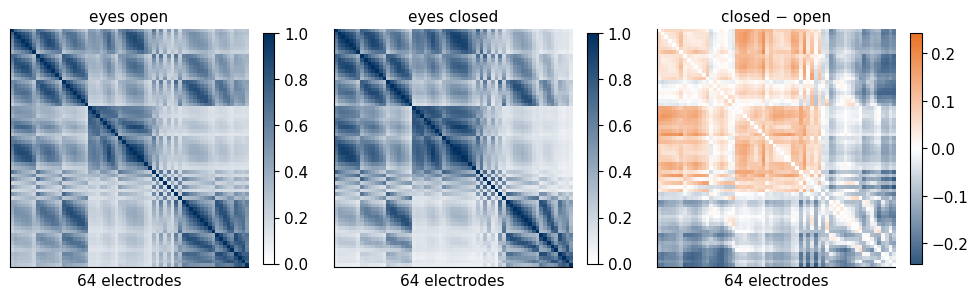

In [17]:
# §4.1 · Alpha (8-12 Hz) amplitude-envelope correlation per person and condition
need("y")
if cont is not None:
    aec = np.zeros((len(SUBJECTS), 2, 64, 64))
    for i, s in enumerate(SUBJECTS):
        for lab in (0, 1):
            xa = mne.filter.filter_data(cont[(s, lab)], SFREQ, ALPHA_ENV[0], ALPHA_ENV[1], fir_design="firwin")
            n = xa.shape[-1]
            env = np.abs(hilbert(xa, N=next_fast_len(n), axis=-1)[:, :n])     # envelope (as MNE computes it)
            nw = n // WIN
            e = env[:, :nw * WIN].reshape(64, nw, WIN).transpose(1, 0, 2)   # windows x channels x samples
            zc = (e - e.mean(-1, keepdims=True)) / e.std(-1, keepdims=True)
            aec[i, lab] = np.einsum("wct,wdt->cd", zc, zc) / (nw * WIN)     # mean correlation over windows
else:
    aec = fb["aec_win"].astype(float)                                       # precomputed, same recipe
iu = np.triu_indices(64, 1)
off = aec[:, :, iu[0], iu[1]].mean(-1)                                      # (people, condition)
show("mean envelope correlation, eyes open", off[:, 0].mean(), key="graph_aec_mean_offdiag_eyes_open")
show("mean envelope correlation, eyes closed", off[:, 1].mean(), key="graph_aec_mean_offdiag_eyes_closed")
show("people with a higher value with eyes closed", (off[:, 1] > off[:, 0]).sum(),
     key="graph_aec_n_subjects_EC_greater_than_EO", nd=0)
p_aec = wilcoxon(off[:, 1], off[:, 0]).pvalue
show("Wilcoxon signed-rank test over the 20 people, p", p_aec, key="graph_aec_wilcoxon_p_two_sided")
aec_eo, aec_ec = aec[:, 0].mean(0), aec[:, 1].mean(0)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
v_d = np.abs(aec_ec - aec_eo).max()                     # symmetric limits for the difference
for ax, M, ttl, cm, (lo, hi) in ((axs[0], aec_eo, "eyes open", WHITE_NAVY, (0, 1)),
                                 (axs[1], aec_ec, "eyes closed", WHITE_NAVY, (0, 1)),
                                 (axs[2], aec_ec - aec_eo, "closed − open", DIVERGING, (-v_d, v_d))):
    im = ax.imshow(M, cmap=cm, vmin=lo, vmax=hi)
    ax.set_title(ttl, fontsize=11); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("64 electrodes")
    plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout(); plt.show()

**What you should see.** Mean envelope correlation 0.43 with eyes open vs
0.41 with eyes closed, higher with eyes closed in only
10 of 20 people (Wilcoxon p = 0.60): a
6× change in power, no reliable change in the
graph.

**§4.2 · Which electrodes do the strongest edges join?**

one threshold for both panels: r >= 0.82
threshold: 0.82  · lecture run 0.82
edges, eyes open: 86  · lecture run 86
edges, eyes closed: 116  · lecture run 116
edges in both: 81  · lecture run 81
median distance of the drawn edges (cm): 3.8  · lecture run 3.8
median distance of all pairs (cm): 12.7  · lecture run 12.7
median distance to the nearest electrode (cm): 3.1  · lecture run 3.1
share of drawn edges shorter than 5 cm: 0.74  · lecture run 0.74
Spearman ρ, edge strength vs distance, eyes open: −0.89  · lecture run −0.89
Spearman ρ, edge strength vs distance, eyes closed: −0.85  · lecture run −0.85


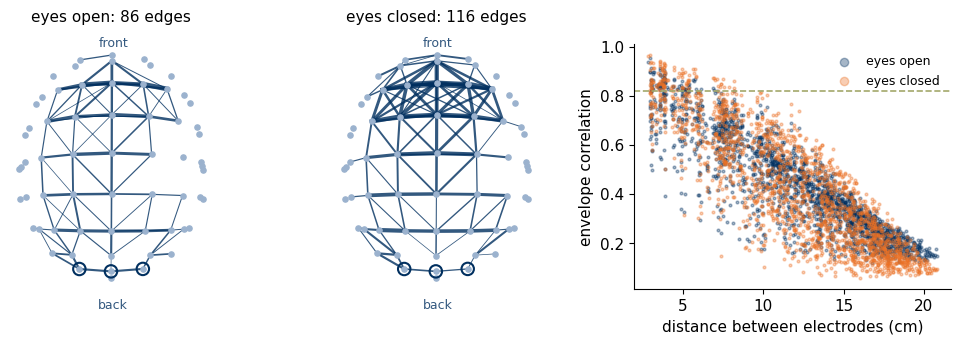

In [18]:
# §4.2 · Head graphs at one threshold (top 5% of the pooled edges) and edge strength vs electrode distance
need("aec")
pair_eo, pair_ec = aec_eo[iu], aec_ec[iu]
thr = np.percentile(np.r_[pair_eo, pair_ec], 95)                  # one threshold for both panels
top_eo, top_ec = pair_eo >= thr, pair_ec >= thr
dist = np.linalg.norm(ch_pos[:, None] - ch_pos[None], axis=-1) * 100     # cm between template electrode positions
pair_d = dist[iu]
d_top = np.r_[pair_d[top_eo], pair_d[top_ec]]
print(f"one threshold for both panels: r >= {thr:.2f}")
show("threshold", thr, key="graph_aec_top5pct_threshold_pooled")
show("edges, eyes open", top_eo.sum(), key="graph_aec_top5pct_n_edges_eyes_open", nd=0)
show("edges, eyes closed", top_ec.sum(), key="graph_aec_top5pct_n_edges_eyes_closed", nd=0)
show("edges in both", (top_eo & top_ec).sum(), key="graph_aec_top5pct_n_edges_in_both", nd=0)
show("median distance of the drawn edges (cm)", np.median(d_top), key="graph_aec_top5pct_median_distance_cm", nd=1)
show("median distance of all pairs (cm)", np.median(pair_d), key="graph_allpairs_median_distance_cm", nd=1)
show("median distance to the nearest electrode (cm)", np.median(np.where(np.eye(64, dtype=bool), np.inf, dist).min(1)),
     key="graph_nearest_neighbour_distance_cm_median", nd=1)
show("share of drawn edges shorter than 5 cm", np.mean(d_top < 5), key="graph_aec_top5pct_frac_edges_shorter_than_5cm")
rho_eo, rho_ec = spearmanr(pair_eo, pair_d).statistic, spearmanr(pair_ec, pair_d).statistic
show("Spearman ρ, edge strength vs distance, eyes open", rho_eo, key="graph_aec_spearman_vs_distance_eo")
show("Spearman ρ, edge strength vs distance, eyes closed", rho_ec, key="graph_aec_spearman_vs_distance_ec")
note("connect", off[:, 0].mean(), off[:, 1].mean(), p_aec, np.median(d_top), np.median(pair_d))

xy = ch_pos[:, :2] * 100
ring = [ch_names.index(c) for c in OCC]
fig, axs = plt.subplots(1, 3, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for ax, top, pv, ttl in ((axs[0], top_eo, pair_eo, "eyes open"), (axs[1], top_ec, pair_ec, "eyes closed")):
    for k in np.flatnonzero(top):
        a_, b_ = iu[0][k], iu[1][k]
        ax.plot(*xy[[a_, b_]].T, color=NAVY, lw=4 * (pv[k] - thr) / (1 - thr) + 0.5, alpha=0.8)
    ax.scatter(*xy.T, s=14, color=GREYBLUE, zorder=3)
    ax.scatter(*xy[ring].T, s=80, facecolors="none", edgecolors=NAVY, lw=1.5, zorder=4)
    ax.set_title(f"{ttl}: {top.sum()} edges", fontsize=11, pad=16); ax.set_aspect("equal"); ax.axis("off")
    ax.text(0, xy[:, 1].max() + 0.8, "front", ha="center", color=STEEL, fontsize=9)
    ax.text(0, xy[:, 1].min() - 2.0, "back", ha="center", va="top", color=STEEL, fontsize=9)
ax = axs[2]
ax.scatter(pair_d, pair_eo, s=4, color=EO_C, alpha=0.35, label="eyes open")
ax.scatter(pair_d, pair_ec, s=4, color=EC_C, alpha=0.35, label="eyes closed")
ax.axhline(thr, color=OLIVE, ls="--", lw=1.2)
ax.set_xlabel("distance between electrodes (cm)"); ax.set_ylabel("envelope correlation")
ax.legend(frameon=False, markerscale=3, fontsize=9)
plt.tight_layout(); plt.show()

**What you should see.** One threshold (r ≥ 0.82) gives
86 edges with eyes open and 116 with
eyes closed (81 in both). The strongest edges join **neighbours**: median
3.8 cm, against 12.7 cm for all
pairs (the nearest electrode is 3.1 cm away);
74% of them are shorter than 5 cm. Edge strength falls
with distance (ρ −0.89 open, −0.85 closed).

Neighbouring electrodes pick up the same sources (**volume conduction**) and share a reference, so a high zero-lag
correlation can appear without any interaction between brain areas. Real coupling between neighbouring cortex would
also fall with distance, and at the sensor level we cannot separate the two: the strongest edges **may reflect physics
rather than brain coupling**. A correlation is not a wire. Measures that ignore zero-lag coupling (imaginary coherence,
wPLI) or an analysis in source space help (source space does not remove the problem).

**Trust check · CONFOUND.**

## §5 · The forehead puzzle

**§5.1 · Decode the eyes from the forehead only.** The break puzzle, now on your screen: Fp1, Fpz and Fp2 sit on the
forehead, far from visual cortex.

**Predict:** *with only these 3 electrodes, near chance (0.50) or as good as all 64 (0.75)? And without the alpha
band?*

forehead, all frequencies (120 features): 0.75 ± 0.04 (75%)  · lecture run 0.75 ± 0.04
forehead without 8-13 Hz (102): 0.71 ± 0.04 (71%)  · lecture run 0.71 ± 0.04
back of the head, alpha bins (18): 0.72 ± 0.08 (72%)  · lecture run 0.72 ± 0.08
all 64 channels (§2.2): 0.75


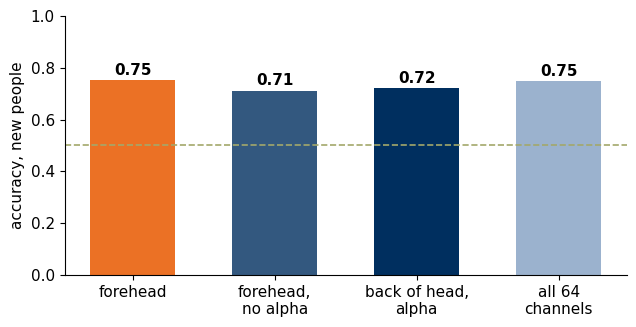

In [19]:
# §5.1 · Person-grouped accuracy from the forehead only, with and without the alpha band
need("F_full")
F_front = logP[:, front].reshape(len(y), -1)                               # 3 channels x 40 frequencies
F_front_noalpha = logP[:, front][:, :, ~in_band(*ALPHA)].reshape(len(y), -1)
F_occ_alpha = logP[:, occ][:, :, in_band(*ALPHA)].reshape(len(y), -1)
acc_front, acc_front_na, acc_occ = cv_acc(F_front), cv_acc(F_front_noalpha), cv_acc(F_occ_alpha)
show_cv(f"forehead, all frequencies ({F_front.shape[1]} features)", acc_front, prefix="clf_frontal_Fp1_Fpz_Fp2_all_freqs_honest")
show_cv(f"forehead without 8-13 Hz ({F_front_noalpha.shape[1]})", acc_front_na, prefix="clf_frontal_without_8_13Hz_honest")
show_cv(f"back of the head, alpha bins ({F_occ_alpha.shape[1]})", acc_occ, prefix="clf_occipital_O1_Oz_O2_alpha_bins_honest")
print(f"all 64 channels (§2.2): {acc_full.mean():.2f}" if globals().get("acc_full") is not None else "")
note("forehead", acc_front.mean(), acc_front_na.mean())
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = [(acc_front, ORANGE, "forehead"), (acc_front_na, STEEL, "forehead,\nno alpha"),
        (acc_occ, NAVY, "back of head,\nalpha"), (cv_acc(F_full) if globals().get("acc_full") is None else acc_full,
                                                  GREYBLUE, "all 64\nchannels")]
for k, (sc, col, name) in enumerate(bars):
    ax.bar(k, sc.mean(), color=col, width=0.6)
    ax.text(k, sc.mean() + 0.02, f"{sc.mean():.2f}", ha="center", fontweight="bold")
ax.axhline(0.5, color=OLIVE, ls="--", lw=1.2)
ax.set_xticks(range(4), [b[2] for b in bars]); ax.set_ylim(0, 1); ax.set_ylabel("accuracy, new people")
plt.tight_layout(); plt.show()

**What you should see.** The forehead alone gives 0.75 ±
0.04 — as good as all 64 channels
(0.75) — and still 0.71 without the alpha
band (the occipital alpha bins: 0.72). So what does the forehead see?

**§5.2 · Why: slow power on the forehead.**

people with more slow power with eyes OPEN: 16  · lecture run 16
ratio open / closed (geometric mean): 3.5  · lecture run 3.5
Wilcoxon p: 0.0005  · lecture run 0.0005
this single feature, new people: 0.61 ± 0.08 (61%)  · lecture run 0.61 ± 0.08


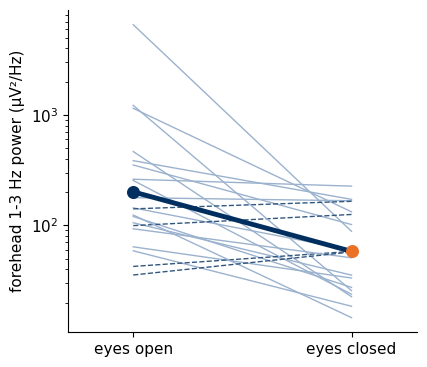

In [20]:
# §5.2 · Slow (1-3 Hz) power over Fp1/Fpz/Fp2, eyes open vs closed, per person
need("logP")
slow = logP[:, front][:, :, in_band(*SLOW_FRONT)].mean(axis=(1, 2))     # log10 µV²/Hz per window
s_eo, s_ec = per_person(slow, 0), per_person(slow, 1)
show("people with more slow power with eyes OPEN", (s_eo > s_ec).sum(), key="frontal_delta_n_subjects_EO_greater_than_EC", nd=0)
show("ratio open / closed (geometric mean)", 10 ** (s_eo - s_ec).mean(), key="frontal_delta_power_ratio_EO_over_EC_geometric_mean", nd=1)
show("Wilcoxon p", wilcoxon(s_eo, s_ec).pvalue, key="frontal_delta_wilcoxon_p_two_sided", nd=4)
show_cv("this single feature, new people", cv_acc(slow[:, None]), prefix="clf_frontal_delta_1_3Hz_mean_logpower_honest")
fig, ax = plt.subplots(figsize=(4.4, 3.8))
for a_, b_ in zip(s_eo, s_ec):
    falls = a_ > b_
    ax.plot([0, 1], [10 ** a_, 10 ** b_], color=GREYBLUE if falls else STEEL, ls="-" if falls else "--", lw=1)
ax.plot([0, 1], [10 ** s_eo.mean(), 10 ** s_ec.mean()], color=NAVY, lw=3.5)
ax.scatter([0], [10 ** s_eo.mean()], color=EO_C, s=70, zorder=4); ax.scatter([1], [10 ** s_ec.mean()], color=EC_C, s=70, zorder=4)
ax.set_yscale("log"); ax.set_xticks([0, 1], ["eyes open", "eyes closed"]); ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("forehead 1-3 Hz power (µV²/Hz)")
plt.tight_layout(); plt.show()

**What you should see.** Slow forehead power is higher with eyes **open** in 16
of 20 people, about 3.5× (Wilcoxon p =
0.0005); that single feature gives 0.61.

Open eyes blink and move, and those artefacts are large and slow at the forehead: the model **most likely reads the
eyes rather than the brain** (an inference — no eye channel was recorded; a "Clever Hans" model). Slow power alone gives
only 0.61, so the rest may come from muscle or from alpha spreading
forward. The fix: remove eye artefacts (e.g. ICA), record an eye channel, or check which channels and frequencies the
model uses.

**Trust check · CONFOUND.**

## §6 · fMRI: child or adult from a brain graph — and is it head motion?

**Jump here** when the professor says so. Needs only §0.

**§6.1 · The data: 155 people watching the same short film.** BOLD fMRI measures blood oxygenation,
a slow echo of neural activity that peaks about 5 s later; here one image every 2 s. An **atlas**
pools the voxels into regions, so each person becomes a multivariate time series. The MSDL atlas
(39 regions) was made by *dictionary learning* (Varoquaux et al. 2011); other atlases (BASC,
Craddock et al. 2012) are made by clustering voxels (a link to §3.2).
*Data:* Richardson et al. 2018; OpenNeuro ds000228; nilearn derivative (OSF 5hju4); CC BY 4.0.

In [21]:
# §6.1 · Load the fMRI file of §0.3: region time series, age, group and head motion of 155 people
need("fmri_path")
dev = np.load(fmri_path, allow_pickle=False)
ts = dev["ts"].astype(np.float64)                     # (people, images, regions)
age = dev["age"].astype(float)
is_adult = dev["child_adult"] == "adult"
y_dev = is_adult.astype(int)                          # 1 = adult (the positive class), 0 = child
fd_mean = dev["fd_mean"].astype(float)                # mean framewise displacement (mm)
roi_labels, networks, coords, ids = dev["labels"], dev["networks"], dev["coords"], dev["participant_id"]
n_p, n_t, n_r = ts.shape
print(f"{n_p} people: {(~is_adult).sum()} children ({age[~is_adult].min():.1f}-{age[~is_adult].max():.1f} y), "
      f"{is_adult.sum()} adults ({age[is_adult].min():.0f}-{age[is_adult].max():.0f} y)")
print(f"{n_t} images × {float(dev['t_r']):g} s = {n_t * float(dev['t_r']):.0f} s ({n_t * float(dev['t_r']) / 60:.1f} min); "
      f"{n_r} regions -> {n_r * (n_r - 1) // 2} edges")
show("children", (~is_adult).sum(), key="dev_n_children", nd=0)
show("adults", is_adult.sum(), key="dev_n_adults", nd=0)

155 people: 122 children (3.5-12.3 y), 33 adults (18-39 y)
168 images × 2 s = 336 s (5.6 min); 39 regions -> 741 edges
children: 122  · lecture run 122
adults: 33  · lecture run 33


**What you should see.** 155 people: 122 children (3.5–12.3 y)
and 33 adults (18–39 y); 168
images × 2 s = 336 s; 39 regions → 741 edges.

**§6.2 · One person = a 39-channel time series; one correlation matrix = a graph.** Connectivity
features again, now on brain regions: correlating every pair of regions gives each person a **connectome**, one graph with
741 numbers. Partial correlation would remove links explained by a third region; here we stay with
plain correlation (extra exercise 7 tries the other). The two people shown are chosen by a rule: the closest to their
group's median age and median head motion.

typical child: sub-pixar054 (6 y), typical adult: sub-pixar151 (23 y)
index of the typical child: 150  · lecture run 150
index of the typical adult: 25  · lecture run 25
mean correlation, adults: 0.087  · lecture run 0.087
mean correlation, children: 0.115  · lecture run 0.115


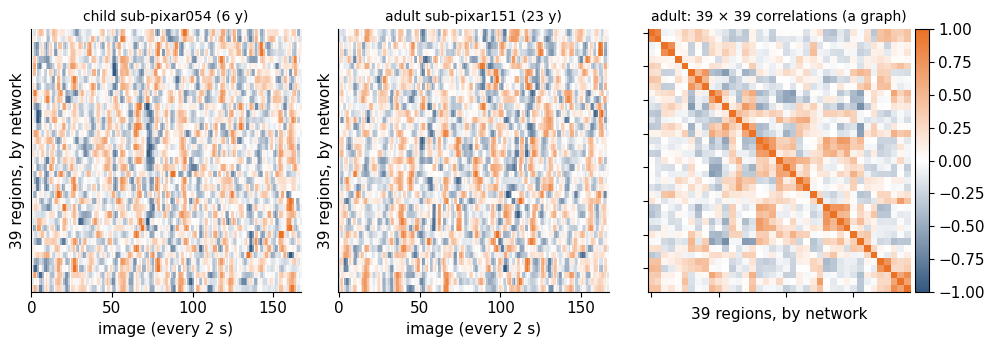

In [22]:
# §6.2 · Carpet plots of a typical child and a typical adult, and the adult's 39 x 39 correlation matrix
need("ts")


def typical(mask):
    "The person closest to the group's median age and median motion (each scaled by the group's IQR)."
    cand = np.flatnonzero(mask)
    a_, f_ = age[cand], fd_mean[cand]
    iqr = lambda v: np.subtract(*np.percentile(v, [75, 25]))
    return int(cand[np.argmin(np.hypot((a_ - np.median(a_)) / iqr(a_), (f_ - np.median(f_)) / iqr(f_)))])


i_child, i_adult = typical(~is_adult), typical(is_adult)
print(f"typical child: {ids[i_child]} ({age[i_child]:.0f} y), typical adult: {ids[i_adult]} ({age[i_adult]:.0f} y)")
show("index of the typical child", i_child, key="dev_example_child_typical_index", nd=0)
show("index of the typical adult", i_adult, key="dev_example_adult_typical_index", nd=0)
order_r = np.argsort(networks, kind="stable")          # regions grouped by network
conn = ConnectivityMeasure(kind="correlation").fit_transform(ts)       # one 39 x 39 matrix per person
iu_r = np.triu_indices(n_r, 1)
show("mean correlation, adults", conn[is_adult].mean(0)[iu_r].mean(), key="dev_meanconn_mean_offdiag_adults", nd=3)
show("mean correlation, children", conn[~is_adult].mean(0)[iu_r].mean(), key="dev_meanconn_mean_offdiag_children", nd=3)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.05]})
for ax, i, name in ((axs[0], i_child, "child"), (axs[1], i_adult, "adult")):
    ax.imshow(ts[i][:, order_r].T, aspect="auto", cmap=DIVERGING, vmin=-3, vmax=3, interpolation="nearest")
    ax.set_title(f"{name} {ids[i]} ({age[i]:.0f} y)", fontsize=10)
    ax.set_xlabel("image (every 2 s)"); ax.set_ylabel("39 regions, by network")
    ax.set_yticks([])
plotting.plot_matrix(conn[i_adult][np.ix_(order_r, order_r)], axes=axs[2], cmap=DIVERGING, vmin=-1, vmax=1,
                     colorbar=True)
axs[2].set_title("adult: 39 × 39 correlations (a graph)", fontsize=10)
axs[2].set_xlabel("39 regions, by network")
plt.tight_layout(); plt.show()

**What you should see.** Two carpets of slow fluctuations (rows = regions, columns = images) and a
39 × 39 matrix whose 741 numbers above the diagonal are the
edges of this person's graph. Averaged over people, the correlations are a little weaker in adults
(0.087) than in children (0.115).

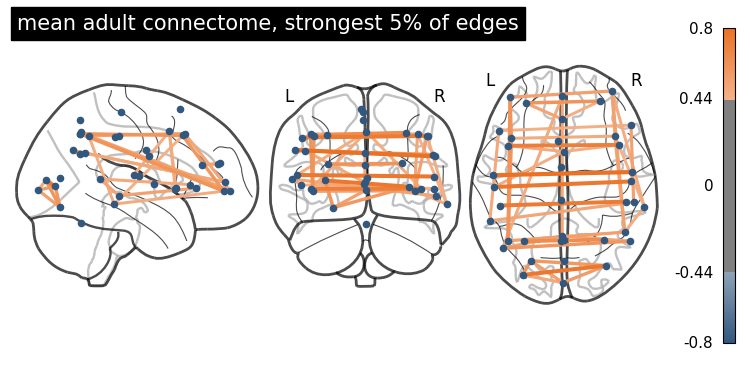

In [23]:
# §6.2b · (optional) The mean adult connectome on a glass brain: only the strongest 5% of the edges
need("conn")
plotting.plot_connectome(conn[is_adult].mean(0), coords, edge_threshold="95%", node_size=20, node_color=STEEL,
                         edge_cmap=DIVERGING,
                         title="mean adult connectome, strongest 5% of edges")
plt.show()

**§6.3 · Predict: what does "answer child for everyone" score?** Definitions: **balanced accuracy** = the average of the accuracy within each group (children, adults);
**AUC** = the probability that a random adult gets a higher "adult" score than a random child (0.5 = chance,
1 = perfect). The test: 5 folds × 10 repeats over people, each fold keeps about 31
people out (about 7 adults).

**Predict:** *accuracy, balanced accuracy and AUC of the model that always says "child".*

accuracy: 0.79 (79%)  · lecture run 0.79
balanced accuracy: 0.50 (50%)  · lecture run 0.50
AUC: 0.50  · lecture run 0.50


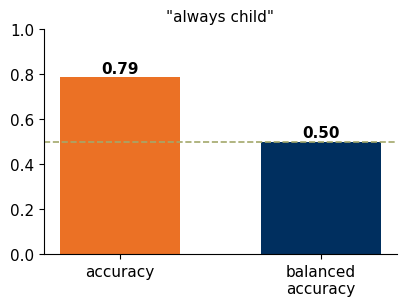

In [24]:
# §6.3 · The "always child" model under the fMRI protocol (50 test folds)
need("ts")
res_dummy = fmri_cv(DummyClassifier(strategy="most_frequent"), fd_mean[:, None], y_dev)
show("accuracy", res_dummy["acc"].mean(), key="dev_cls_all_dummy_acc_mean", pct=True)
show("balanced accuracy", res_dummy["bal_acc"].mean(), key="dev_cls_all_dummy_bal_acc_mean", pct=True)
show("AUC", res_dummy["auc"].mean(), key="dev_cls_all_dummy_auc_mean")
fig, ax = plt.subplots(figsize=(4.2, 3.2))
for k, (v, col, name) in enumerate(((res_dummy["acc"].mean(), ORANGE, "accuracy"),
                                    (res_dummy["bal_acc"].mean(), NAVY, "balanced\naccuracy"))):
    ax.bar(k, v, color=col, width=0.6); ax.text(k, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold")
ax.axhline(0.5, color=OLIVE, ls="--", lw=1.2)
ax.set_xticks([0, 1], ["accuracy", "balanced\naccuracy"]); ax.set_ylim(0, 1); ax.set_title('"always child"', fontsize=11)
plt.tight_layout(); plt.show()

**What you should see.** Accuracy 0.79 (= 122/155,
the share of children) with no knowledge at all; balanced accuracy 0.50 and AUC
0.50.

**Trust check · METRIC:** with unequal groups, accuracy hides the small group.

**§6.4 · Connectome → logistic regression.** Featurization again: the same logistic regression as in §2, now with
741 edge strengths as features. Two ways to build the graph: plain **correlation**, and the **tangent space**: connectomes live on a curved
surface, and the tangent space measures each one from the group average, so that a linear model can use them. The
group average is computed on the training people only, inside each fold.

**Predict:** *above "always child" in balanced accuracy? Which graph is better?*

correlation  accuracy: 0.95  · lecture run 0.95
correlation  balanced accuracy: 0.91 ± 0.07 (91%)  · lecture run 0.91 ± 0.07
correlation  AUC: 0.96  · lecture run 0.96
tangent      accuracy: 0.96  · lecture run 0.96
tangent      balanced accuracy: 0.92 ± 0.06 (92%)  · lecture run 0.92 ± 0.06
tangent      AUC: 0.96  · lecture run 0.96


,accuracy,balanced accuracy,AUC
"""always child""",0.79,0.50,0.50
correlation,0.95,0.91,0.96
tangent,0.96,0.92,0.96


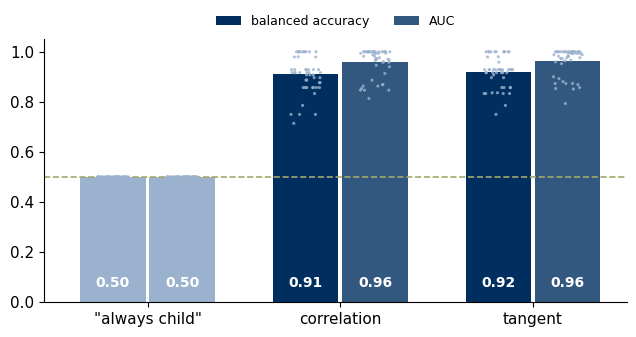

In [25]:
# §6.4 · Correlation and tangent connectomes -> logistic regression (50 folds; this cell takes a little longer)
need("res_dummy")
res_conn = {kind: fmri_cv(fmri_clf(kind), ts, y_dev) for kind in ("correlation", "tangent")}
for kind, r in res_conn.items():
    show(f"{kind:12s} accuracy", r["acc"].mean(), key=f"dev_cls_all_{kind}_acc_mean")
    show_cv(f"{kind:12s} balanced accuracy", r["bal_acc"], prefix=f"dev_cls_all_{kind}_bal_acc")
    show(f"{kind:12s} AUC", r["auc"].mean(), key=f"dev_cls_all_{kind}_auc_mean")
note("fmri_group", res_dummy["acc"].mean(), res_dummy["bal_acc"].mean(), res_conn["tangent"]["bal_acc"].mean(),
     res_conn["tangent"]["auc"].mean())
display(pd.DataFrame({name: [r["acc"].mean(), r["bal_acc"].mean(), r["auc"].mean()] for name, r in
                      (('"always child"', res_dummy), ("correlation", res_conn["correlation"]),
                       ("tangent", res_conn["tangent"]))}, index=["accuracy", "balanced accuracy", "AUC"]).T.round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
groups_ = [('"always child"', res_dummy), ("correlation", res_conn["correlation"]), ("tangent", res_conn["tangent"])]
for k, (name, r) in enumerate(groups_):
    for dx, met, col in ((-0.18, "bal_acc", NAVY if k else GREYBLUE), (0.18, "auc", STEEL if k else GREYBLUE)):
        ax.bar(k + dx, r[met].mean(), width=0.34, color=col)
        ax.scatter(k + dx + np.random.default_rng(k).uniform(-0.08, 0.08, len(r[met])), r[met], s=5, color=GREYBLUE,
                   edgecolor="none", zorder=3, alpha=0.8)
        ax.text(k + dx, 0.06, f"{r[met].mean():.2f}", ha="center", fontsize=10, fontweight="bold", color="white")
ax.axhline(0.5, color=OLIVE, ls="--", lw=1.2)
ax.set_xticks(range(3), [n for n, _ in groups_]); ax.set_ylim(0, 1.05)
ax.bar(0, 0, color=NAVY, label="balanced accuracy"); ax.bar(0, 0, color=STEEL, label="AUC")
ax.legend(frameon=False, fontsize=9, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()

**What you should see.**

| Connectome | Accuracy | Balanced accuracy | AUC |
|---|---|---|---|
| "always child" | 0.79 | 0.50 | 0.50 |
| correlation | 0.95 | 0.91 ± 0.07 | 0.96 |
| tangent | 0.96 | **0.92 ± 0.06** | **0.96** |

Scored fairly, the connectome tells children from adults far above chance. (The ± values are SDs over the 50 folds, not
standard errors: the folds overlap.)

**§6.5 · Is it just head motion?** Children move more in the scanner, and motion changes correlations. Could the
model be reading motion instead of the brain? Mean **framewise displacement** (FD) = how much the head moves from one
image to the next, in mm.

**Predict:** *how well does head motion alone tell children from adults? And the connectome, once children and adults
move equally?*

mean FD, children (mm): 0.37  · lecture run 0.37
mean FD, adults (mm): 0.19  · lecture run 0.19
Mann-Whitney p = 8.0e-06  · lecture run 8.0e-06
motion only: balanced accuracy: 0.69  · lecture run 0.69
motion only: AUC: 0.75  · lecture run 0.75
matched: mean FD, children (mm): 0.188  · lecture run 0.188
matched: mean FD, adults (mm): 0.187  · lecture run 0.187


matched (66 people), motion_only: balanced accuracy: 0.43  · lecture run 0.43
matched (66 people), motion_only: AUC: 0.39  · lecture run 0.39
matched (66 people), correlation: balanced accuracy: 0.91  · lecture run 0.91
matched (66 people), correlation: AUC: 0.96  · lecture run 0.96
matched (66 people), tangent: balanced accuracy: 0.92  · lecture run 0.92
matched (66 people), tangent: AUC: 0.96  · lecture run 0.96


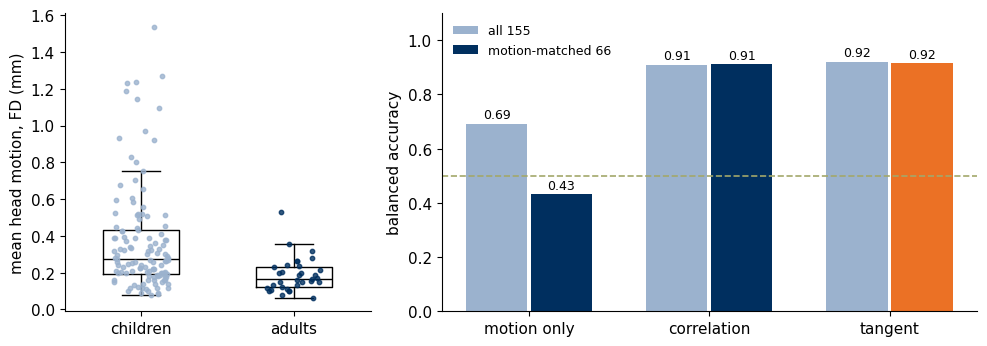

In [26]:
# §6.5 · Motion per group, a motion-only model, and the same models on a motion-matched subset
need("res_conn")
show("mean FD, children (mm)", fd_mean[~is_adult].mean(), key="dev_fd_mean_children_mean_mm")
show("mean FD, adults (mm)", fd_mean[is_adult].mean(), key="dev_fd_mean_adults_mean_mm")
p_fd = mannwhitneyu(fd_mean[~is_adult], fd_mean[is_adult]).pvalue
print(f"Mann-Whitney p = {p_fd:.1e}  · lecture run {EXPECTED['dev_fd_children_vs_adults_mannwhitney_p']:.1e}")
CHECK["dev_fd_children_vs_adults_mannwhitney_p"] = float(p_fd)
motion_clf = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
res_motion = fmri_cv(motion_clf, fd_mean[:, None], y_dev)
show("motion only: balanced accuracy", res_motion["bal_acc"].mean(), key="dev_cls_all_motion_only_bal_acc_mean")
show("motion only: AUC", res_motion["auc"].mean(), key="dev_cls_all_motion_only_auc_mean")

# Motion-matched subset: all 33 adults + the 33 children with the closest motion (greedy, without replacement)
adults_idx, children_idx = np.flatnonzero(is_adult), np.flatnonzero(~is_adult)
available, pairs = list(children_idx), []
for a in adults_idx[np.argsort(fd_mean[adults_idx], kind="stable")]:      # adults from lowest to highest motion
    j = int(np.argmin(np.abs(fd_mean[available] - fd_mean[a])))           # the closest unused child
    pairs.append((a, available.pop(j)))
matched_children = np.sort([c for _, c in pairs])
sub = np.r_[adults_idx, matched_children]
show("matched: mean FD, children (mm)", fd_mean[matched_children].mean(), key="dev_matched_fd_children_mean_mm", nd=3)
show("matched: mean FD, adults (mm)", fd_mean[adults_idx].mean(), key="dev_matched_fd_adults_mean_mm", nd=3)
res_m = {"motion_only": fmri_cv(motion_clf, fd_mean[sub, None], y_dev[sub]),
         "correlation": fmri_cv(fmri_clf("correlation"), ts[sub], y_dev[sub]),
         "tangent": fmri_cv(fmri_clf("tangent"), ts[sub], y_dev[sub])}
for name, r in res_m.items():
    show(f"matched ({len(sub)} people), {name}: balanced accuracy", r["bal_acc"].mean(), key=f"dev_cls_matched_{name}_bal_acc_mean")
    show(f"matched ({len(sub)} people), {name}: AUC", r["auc"].mean(), key=f"dev_cls_matched_{name}_auc_mean")
note("fmri_motion", res_motion["bal_acc"].mean(), res_m["motion_only"]["bal_acc"].mean(), res_m["tangent"]["bal_acc"].mean())

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [0.8, 1.4]})
ax = axs[0]
rng = np.random.default_rng(SEED)
for k, (m_, col, name) in enumerate(((~is_adult, CHILD_C, "children"), (is_adult, ADULT_C, "adults"))):
    ax.boxplot(fd_mean[m_], positions=[k], widths=0.5, showfliers=False, medianprops=dict(color="black"))
    ax.scatter(k + rng.uniform(-0.18, 0.18, m_.sum()), fd_mean[m_], s=10, color=col, alpha=0.8, zorder=3)
ax.set_xticks([0, 1], ["children", "adults"]); ax.set_ylabel("mean head motion, FD (mm)")
ax = axs[1]
names = ["motion only", "correlation", "tangent"]
all_v = [res_motion["bal_acc"].mean(), res_conn["correlation"]["bal_acc"].mean(), res_conn["tangent"]["bal_acc"].mean()]
mat_v = [res_m["motion_only"]["bal_acc"].mean(), res_m["correlation"]["bal_acc"].mean(), res_m["tangent"]["bal_acc"].mean()]
for k in range(3):
    ax.bar(k - 0.18, all_v[k], width=0.34, color=GREYBLUE, label="all 155" if k == 0 else None)
    ax.bar(k + 0.18, mat_v[k], width=0.34, color=ORANGE if k == 2 else NAVY, label="motion-matched 66" if k == 0 else None)
    for dx, v in ((-0.18, all_v[k]), (0.18, mat_v[k])):
        ax.text(k + dx, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
ax.axhline(0.5, color=OLIVE, ls="--", lw=1.2)
ax.set_xticks(range(3), names); ax.set_ylim(0, 1.1); ax.set_ylabel("balanced accuracy"); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**What you should see.** Children move about twice as much (FD 0.37 vs
0.19 mm), and motion alone already reaches balanced accuracy
0.69 (AUC 0.75). In the motion-matched subset
(FD 0.188 vs 0.187 mm), motion no longer predicts
the group (0.43; noisy, n = 66), but the tangent
connectome still does (0.92, AUC 0.96).

**Q2:** yes — and the signal survives when motion is matched. But: one site, one film, and two age groups far apart
(3.5–12 vs 18–39 y).

**Trust check · CONFOUND.**

## §7 · fMRI: PREDICT a number — how old is this brain?

**§7.1 · Regression: age from the connectome.** In **regression** the output is a number, not a category.
**Ridge regression** = linear regression (ŷ = w·x + b, a weighted sum as in §2.3 but without the sigmoid) plus a
penalty on large weights (**regularization**); its strength is chosen inside each training fold. **MAE** (mean
absolute error) = how many years the prediction is off, on average. The baseline always predicts the training
people's mean age.

**Predict:** *the baseline is off by about 6 years. How far off will
the connectome be?*

MAE, connectome (years): 3.5  · lecture run 3.5
   ± 0.6 over the 50 folds  · lecture run ± 0.6
MAE, always the mean age (years): 6.2  · lecture run 6.2
Pearson r, predicted vs true age: 0.80  · lecture run 0.80


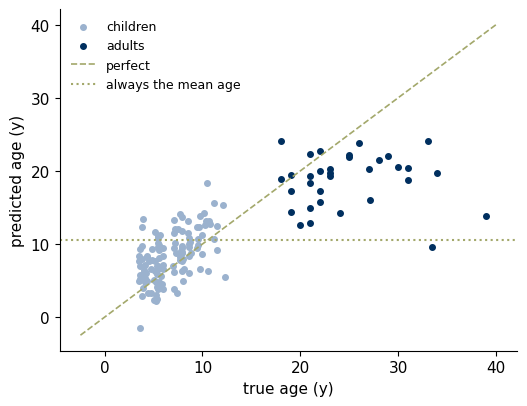

In [27]:
# §7.1 · Tangent connectome -> ridge regression of age; 5 folds x 10 repeats over people (this cell takes a little longer)
need("ts")


def age_model():
    return Pipeline([("connectome", ConnectivityMeasure(kind="tangent", vectorize=True, discard_diagonal=True)),
                     ("scale", StandardScaler()), ("ridge", RidgeCV(alphas=np.logspace(-3, 3, 13)))])


def age_cv(idx):
    Xa, a = ts[idx], age[idx]
    out = {"mae": [], "mae0": [], "r": [], "alpha": []}
    oof = np.zeros((10, len(idx)))
    for k, (tr, te) in enumerate(RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(Xa)):
        m = age_model().fit(Xa[tr], a[tr])
        p = m.predict(Xa[te])
        oof[k // 5, te] = p
        out["mae"].append(np.mean(np.abs(p - a[te])))
        out["mae0"].append(np.mean(np.abs(a[tr].mean() - a[te])))     # always the training mean age
        out["r"].append(pearsonr(p, a[te])[0])
        out["alpha"].append(m.named_steps["ridge"].alpha_)
    out = {k: np.array(v) for k, v in out.items()}
    out["pred"] = oof.mean(0)                                          # out-of-fold prediction, mean over repeats
    return out


age_all = age_cv(np.arange(n_p))
show("MAE, connectome (years)", age_all["mae"].mean(), key="dev_age_all_mae_model_mean_y", nd=1)
print(f"   ± {age_all['mae'].std():.1f} over the 50 folds  · lecture run ± {EXPECTED['dev_age_all_mae_model_sd_y']:.1f}")
CHECK["dev_age_all_mae_model_sd_y"] = float(age_all["mae"].std())
show("MAE, always the mean age (years)", age_all["mae0"].mean(), key="dev_age_all_mae_trainmean_baseline_mean_y", nd=1)
show("Pearson r, predicted vs true age", age_all["r"].mean(), key="dev_age_all_pearson_r_mean")
# (the chosen ridge strength sits at the grid's lower edge in most folds; a wider grid gives the same MAE)
note("fmri_age", age_all["mae"].mean(), age_all["mae0"].mean())
fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.scatter(age[~is_adult], age_all["pred"][~is_adult], s=16, color=CHILD_C, label="children")
ax.scatter(age[is_adult], age_all["pred"][is_adult], s=16, color=ADULT_C, label="adults")
lim = [min(age.min(), age_all["pred"].min()) - 1, max(age.max(), age_all["pred"].max()) + 1]
ax.plot(lim, lim, color=OLIVE, ls="--", lw=1.2, label="perfect")
ax.axhline(age.mean(), color=OLIVE, ls=":", lw=1.5, label="always the mean age")
ax.set_xlabel("true age (y)"); ax.set_ylabel("predicted age (y)"); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**What you should see.** The connectome is off by 3.5 years on average
(± 0.6 over folds) against 6.2 for the
mean age; Pearson r 0.80. But much of this is the child–adult gap; §7.2 asks whether it also
works within the children.

**Trust check · BASELINE.**

In [28]:
# §7.2 · (optional — skip in class) The same regression within the 122 children only
need("ts")
age_ch = age_cv(np.flatnonzero(~is_adult))
show("children only: MAE, connectome (years)", age_ch["mae"].mean(), key="dev_age_children_mae_model_mean_y", nd=1)
show("children only: MAE, always the mean age (years)", age_ch["mae0"].mean(), key="dev_age_children_mae_trainmean_baseline_mean_y", nd=1)
show("children only: Pearson r", age_ch["r"].mean(), key="dev_age_children_pearson_r_mean")

children only: MAE, connectome (years): 1.3  · lecture run 1.3
children only: MAE, always the mean age (years): 2.0  · lecture run 2.0
children only: Pearson r: 0.74  · lecture run 0.74


**What you should see.** Within the children: 1.3 y vs
2.0 y for the mean age (r 0.74):
the connectome also tracks age inside one group.

**§7.3 · REPRESENT without labels: what does the main axis of 155 connectomes follow?** *(optional — skip in class)*
PCA of the 155 tangent connectomes, no labels used.

**Predict:** *will the first axis follow age, or something else?*

variance explained by PC1: 0.050  · lecture run 0.050
Spearman ρ, PC1 vs head motion: −0.71  · lecture run −0.71
Spearman ρ, PC1 vs age: 0.63  · lecture run 0.63
Spearman ρ, PC1 vs age, children only: 0.35  · lecture run 0.35


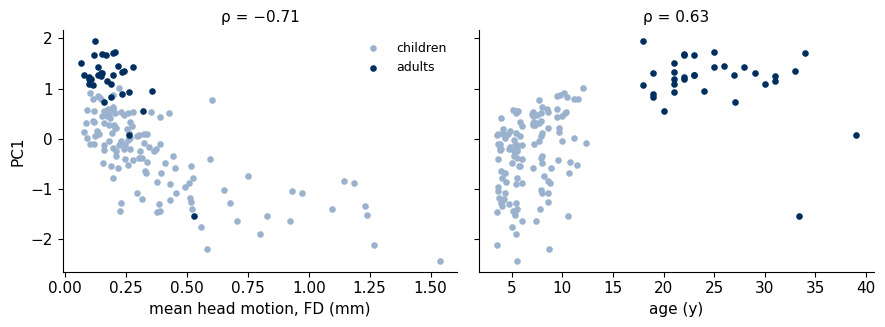

In [29]:
# §7.3 · (optional) PCA of the tangent connectomes of all 155 people; PC1 vs head motion and vs age
need("ts")
tan_all = ConnectivityMeasure(kind="tangent", vectorize=True, discard_diagonal=True).fit_transform(ts)
pca_f = PCA(n_components=5, svd_solver="full", random_state=SEED).fit(tan_all)
pc1 = pca_f.transform(tan_all)[:, 0]
show("variance explained by PC1", pca_f.explained_variance_ratio_[0], key="dev_pca_explained_variance_ratio_pc1", nd=3)
rho_fd, rho_age = spearmanr(pc1, fd_mean).statistic, spearmanr(pc1, age).statistic
show("Spearman ρ, PC1 vs head motion", rho_fd, key="dev_pca_spearman_pc1_meanfd_all")
show("Spearman ρ, PC1 vs age", rho_age, key="dev_pca_spearman_pc1_age_all")
show("Spearman ρ, PC1 vs age, children only", spearmanr(pc1[~is_adult], age[~is_adult]).statistic,
     key="dev_pca_spearman_pc1_age_children")
note("fmri_pca", rho_fd, rho_age)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, v, name, rho in ((axs[0], fd_mean, "mean head motion, FD (mm)", rho_fd), (axs[1], age, "age (y)", rho_age)):
    ax.scatter(v[~is_adult], pc1[~is_adult], s=14, color=CHILD_C, label="children")
    ax.scatter(v[is_adult], pc1[is_adult], s=14, color=ADULT_C, label="adults")
    ax.set_xlabel(name); ax.set_title(f"ρ = {num(rho)}", fontsize=11)
axs[0].set_ylabel("PC1"); axs[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**What you should see.** PC1 explains 5% of the variance and follows
head motion (ρ −0.71) at least as much as age (0.63;
within children only 0.35). An unsupervised representation shows what varies most —
here motion as much as age — not what you hoped to find (the lesson of §3.1 again). **Trust check · CONFOUND.**

## §8 · Your numbers

Compare the table with your neighbours: we look at it together right after the notebook.

- **Q1:** Yes, for a new person about 3 times in 4 (0.50 to
  1.00 depending on the person), and part of that may come from the
  eyes moving rather than from the brain (§5).
- **Q2:** Yes: 0.92 balanced accuracy, also when head motion is matched — on one
  site, one film, and two age groups far apart.

In [30]:
# §8 · Your numbers next to the lecture's ("not run" = you skipped that section)
table = pd.DataFrame([{"§": r["sec"], "Task": r["task"], "Data": r["data"], "What you ran": r["what"],
                       "Your number": MY.get(r["id"], "not run"), "Lecture run": r["lecture"], "Trust check": r["trust"]}
                      for r in ROWS])
highlight = [bool(r.get("highlight")) for r in ROWS]
display(table.style.hide(axis="index")
        .apply(lambda row: ["background-color: #ACDEE6" if highlight[row.name] else "" for _ in row], axis=1)
        .set_properties(**{"text-align": "left"}))
save_check()   # for the lecturer's automatic check only

§,Task,Data,What you ran,Your number,Lecture run,Trust check
§2.2,PREDICT · classify,EEG,"Eyes open or closed, new people: baseline · 1 alpha feature · full spectrum (2,560)",0.50 · 0.64 · 0.75,0.50 · 0.64 · 0.75,BASELINE
§2.2,PREDICT · classify,EEG,Same full-spectrum model: its own training windows vs new people,1.00 vs 0.75,1.00 vs 0.75,—
§2.2,PREDICT · classify,EEG,"Same model, accuracy per held-out person (lowest–highest, median)",0.50–1.00 (median 0.73),0.50–1.00 (median 0.73),UNCERTAINTY
§2.4,PREDICT · classify,EEG,"Same model, windows shuffled across people (gain over the person split, points)",0.91 (+16 points),0.91 (+16 points),SPLIT
§3.1–§3.2,REPRESENT · embed or cluster,EEG,"t-SNE map: silhouette by person vs by eyes · k-means, 2 groups: ARI with eyes",0.32 vs 0.05 · 0.00,0.32 vs 0.05 · 0.00,SPLIT
§3.3,REPRESENT · embed or cluster,EEG,Each person z-scored with all their windows: k-means ARI with eyes · classifier on new people,0.51 · 0.92,0.51 · 0.92,SPLIT
§4,look · connectivity features,EEG,"Alpha envelope correlation, open vs closed (Wilcoxon p) · distance of the strongest edges vs all pairs","0.43 vs 0.41, p = 0.60 · 3.8 vs 12.7 cm","0.43 vs 0.41, p = 0.60 · 3.8 vs 12.7 cm",CONFOUND
§5,PREDICT · classify,EEG,"Forehead only (Fp1, Fpz, Fp2) · forehead without alpha",0.75 · 0.71,0.75 · 0.71,CONFOUND
§6.3–§6.4,PREDICT · classify,fMRI,"Child or adult: ""always child"" accuracy → balanced · connectome (tangent) balanced · AUC",0.79 → 0.50 · 0.92 · 0.96,0.79 → 0.50 · 0.92 · 0.96,METRIC
§6.5,PREDICT · classify,fMRI,"Head motion alone (balanced), all → matched · connectome when motion is matched",0.69 → 0.43 · 0.92,0.69 → 0.43 · 0.92,CONFOUND


**What you should see.** Your column equals the lecture column to ±0.01 (t-SNE silhouettes ±0.03). The highlighted row
is the one to remember: the same model, the same data, +16 points from a
leaky split.

---
# Part B · At home

**§B0 · What is in Part B.** Q3 — where is the rat? 120 hippocampal neurons (§B1); decoding objects from fMRI (§B2);
clustering sleep without the rules (§B3); a Riemannian EEG model (§B4); leakage and luck on pure noise (§B5); a
logistic regression trained by hand (§B6). Each section downloads its own small file (at most 2.5 MB) from the course
repository, checked by its SHA-256 fingerprint, and runs on its own after §0.1–§0.2 (§B4 and §B6 also need the EEG of
§0.4 and §2.1). If you opened the notebook fresh: run §0.1–§0.2 first (*Runtime → Run before*).

In [31]:
# §B0 · Check that the setup cells have run
need("get_repo_file")
print(f"ready · mne {mne.__version__} · nilearn {nilearn.__version__}")

ready · mne 1.11.0 · nilearn 0.13.1


## §B1 · Q3: where is the rat? 120 hippocampal neurons

Rat "Achilles" runs back and forth on a 160-cm linear track while silicon probes
record neurons in hippocampal area CA1 (Grosmark & Buzsáki 2016; DANDI archive 000044; CC BY 4.0). Spike counts come
in 25-ms bins. We keep the 120 excitatory cells (the 17
inhibitory ones are excluded), smooth the counts along time (Gaussian, σ = 50 ms) and use only the bins where the
rat is **running** (on the track and faster than 5 cm/s).

**§B1.1 · Load and build the running bins.**

In [32]:
# §B1.1 · Spike counts, position and running bins
sp = np.load(get_repo_file("achilles_dandi000044_maze_25ms.npz"), allow_pickle=False)
BIN_S = float(sp["bin_s"])                                   # 0.025 s
exc = sp["cell_type"] == "excitatory"
C_full = sp["spikes"][:, exc].astype(float)                  # (bins, 120) spike counts, whole session
pos_full = sp["position"].astype(float) * 100                # cm (negative = off the track)
valid = sp["valid"].astype(bool)                             # the rat is on the track


def segments(mask):
    "Start and stop indices of the runs of True in a boolean vector."
    dd = np.diff(np.r_[0, mask.astype(int), 0])
    return np.flatnonzero(dd == 1), np.flatnonzero(dd == -1)


seg_a, seg_b = segments(valid)
vel_full = np.full(len(valid), np.nan)                       # cm/s, computed inside each on-track stretch
for a_, b_ in zip(seg_a, seg_b):
    if b_ - a_ >= 2:
        vel_full[a_:b_] = np.gradient(gaussian_filter1d(pos_full[a_:b_], 4, mode="nearest"), BIN_S)
with np.errstate(invalid="ignore"):
    running = valid & (np.abs(vel_full) > 5.0)
Xsp = gaussian_filter1d(C_full, 2, axis=0)[running]          # smoothed counts (sigma = 2 bins = 50 ms): the features
S_run, pos, vel = C_full[running], pos_full[running], vel_full[running]
rightward = vel > 0
n_trav = {"right": 0, "left": 0}                             # full runs: >= 120 cm in one direction
for a_, b_ in zip(seg_a, seg_b):
    v_ = vel_full[a_:b_]
    if np.all(np.isnan(v_)):
        continue
    cut = np.flatnonzero(np.diff(np.sign(np.nan_to_num(v_))) != 0) + 1
    for piece in np.split(np.arange(a_, b_), cut):
        if np.ptp(pos_full[piece]) >= 120:
            n_trav["right" if np.nanmean(vel_full[piece]) > 0 else "left"] += 1
print(f"{exc.size} units in the file, {exc.sum()} excitatory cells used")
show("whole session (min)", len(valid) * BIN_S / 60, key="facts.maze_epoch_duration_min", nd=1)
show("running time (min)", running.sum() * BIN_S / 60, key="facts.time_running_min", nd=1)
show("running bins", running.sum(), key="facts.n_bins_running", nd=0)
show("full runs to the right", n_trav["right"], key="facts.n_full_traversals_ge_120cm_right", nd=0)
show("full runs to the left", n_trav["left"], key="facts.n_full_traversals_ge_120cm_left", nd=0)

137 units in the file, 120 excitatory cells used
whole session (min): 34.5  · lecture run 34.5
running time (min): 4.0  · lecture run 4.0
running bins: 9563  · lecture run 9563
full runs to the right: 34  · lecture run 34
full runs to the left: 39  · lecture run 39


**§B1.2 · Place cells: where does each cell fire?** For each cell: spikes per position divided by the time spent there
(5-cm bins, lightly smoothed), separately for each running direction.

cells with a place field, running right: 63  · lecture run 63
cells with a place field, running left: 68  · lecture run 68
in either direction: 84  · lecture run 84


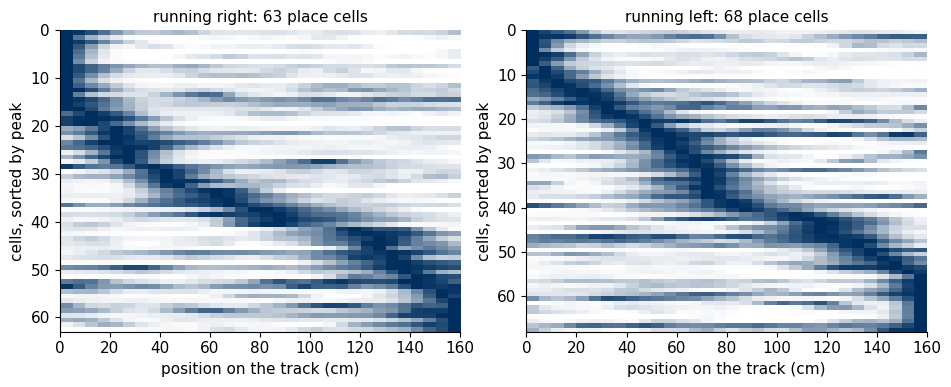

In [33]:
# §B1.2 · Occupancy-normalised rate maps (Hz) per direction; a "place field" = peak rate > 2 Hz
edges_cm = np.arange(0, 160 + 2.5, 5.0)
centres_cm = edges_cm[:-1] + 2.5
pbin = np.clip(np.digitize(pos, edges_cm) - 1, 0, len(centres_cm) - 1)


def rate_map(sel):
    occ_ = np.bincount(pbin[sel], minlength=len(centres_cm)) * BIN_S             # seconds per position bin
    cnt_ = np.zeros((len(centres_cm), S_run.shape[1]))
    np.add.at(cnt_, pbin[sel], S_run[sel])                                      # spikes per position bin
    return (gaussian_filter1d(cnt_, 1.0, axis=0, mode="nearest")
            / gaussian_filter1d(occ_, 1.0, mode="nearest")[:, None]).T          # cells x positions


maps = {"right": rate_map(rightward), "left": rate_map(~rightward), "both": rate_map(np.ones(len(pos), bool))}
peak = {k: m.max(1) for k, m in maps.items()}
peak_pos = {k: centres_cm[m.argmax(1)] for k, m in maps.items()}
show("cells with a place field, running right", (peak["right"] > 2).sum(), key="place_fields.n_cells_peak_gt_2hz_right", nd=0)
show("cells with a place field, running left", (peak["left"] > 2).sum(), key="place_fields.n_cells_peak_gt_2hz_left", nd=0)
show("in either direction", ((peak["right"] > 2) | (peak["left"] > 2)).sum(),
     key="place_fields.n_cells_peak_gt_2hz_either_direction", nd=0)
fig, axs = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, k in zip(axs, ("right", "left")):
    cells = np.flatnonzero(peak[k] > 2)
    cells = cells[np.argsort(peak_pos[k][cells], kind="stable")]
    ax.imshow(maps[k][cells] / peak[k][cells, None], aspect="auto", cmap=WHITE_NAVY,
              extent=[0, 160, len(cells), 0], interpolation="nearest")
    ax.set_xlabel("position on the track (cm)"); ax.set_ylabel("cells, sorted by peak")
    ax.set_title(f"running {k}: {len(cells)} place cells", fontsize=11)
plt.tight_layout(); plt.show()

**What you should see.** A diagonal: each cell fires at its own place, and together the cells tile the track
(63 place cells running right, 68
left). Many cells fire in one direction only.

**§B1.3 · PREDICT a number again: decode the position.** A regression, as in §7. **R²** measures how good a numeric
prediction is: 1 = perfect, 0 = as good as always predicting the mean. Two ways to test: 5 **contiguous blocks of
time** (honest: the test stretch was never seen) or 5 folds of **shuffled bins** (neighbouring 25-ms bins are almost
copies of each other).

**Predict:** *contiguous blocks vs shuffled bins: how well can we read the position from 120 neurons?*

kNN, contiguous blocks: R²: 0.82  · lecture run 0.82
kNN, contiguous blocks: mean error (cm): 12.9  · lecture run 12.9
ridge, contiguous blocks: R²: 0.80  · lecture run 0.80
kNN, shuffled bins: R²: 0.95  · lecture run 0.95
kNN, shuffled bins: mean error (cm): 6.4  · lecture run 6.4
ridge, shuffled bins: R²: 0.85  · lecture run 0.85
baseline (training mean), blocks: R²: −0.005  · lecture run −0.005
baseline, blocks: mean error (cm): 42.4  · lecture run 42.4
direction, contiguous blocks: balanced accuracy: 0.92  · lecture run 0.92


direction, shuffled bins: balanced accuracy: 0.97  · lecture run 0.97
direction: majority rate: 0.547  · lecture run 0.547


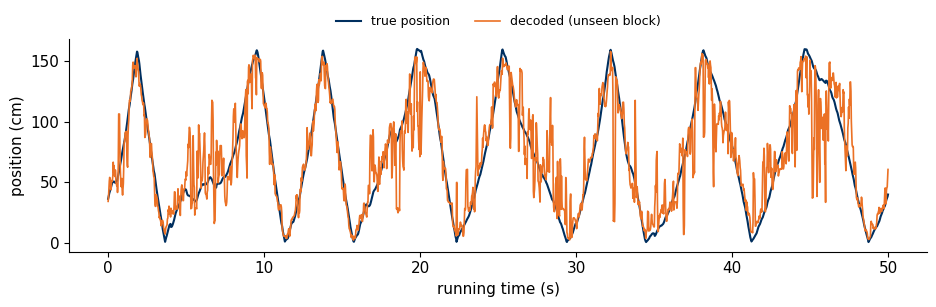

In [34]:
# §B1.3 · Position from the population (kNN and ridge) and running direction (logistic regression)
CV_BLOCKS, CV_SHUF = KFold(5, shuffle=False), KFold(5, shuffle=True, random_state=SEED)


def oof_predict(model, Xa, ya, cv):
    "Out-of-fold predictions: each bin is predicted by a model that did not train on its fold."
    pred = np.empty(len(ya))
    for tr, te in cv.split(Xa):
        pred[te] = clone(model).fit(Xa[tr], ya[tr]).predict(Xa[te])
    return pred


knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=KFold(5, shuffle=False)))
pred = {}
for cvn, cv in (("honest", CV_BLOCKS), ("leaky", CV_SHUF)):
    for mn, model in (("knn10", knn), ("ridgecv", ridge), ("baseline_train_mean", DummyRegressor(strategy="mean"))):
        pred[(cvn, mn)] = oof_predict(model, Xsp, pos, cv)
for cvn, label in (("honest", "contiguous blocks"), ("leaky", "shuffled bins")):
    show(f"kNN, {label}: R²", r2_score(pos, pred[(cvn, "knn10")]), key=f"decoding_position.{cvn}_knn10.r2_pooled")
    show(f"kNN, {label}: mean error (cm)", mean_absolute_error(pos, pred[(cvn, "knn10")]),
         key=f"decoding_position.{cvn}_knn10.mae_cm_pooled", nd=1)
    show(f"ridge, {label}: R²", r2_score(pos, pred[(cvn, "ridgecv")]), key=f"decoding_position.{cvn}_ridgecv.r2_pooled")
show("baseline (training mean), blocks: R²", r2_score(pos, pred[("honest", "baseline_train_mean")]),
     key="decoding_position.honest_baseline_train_mean.r2_pooled", nd=3)
show("baseline, blocks: mean error (cm)", mean_absolute_error(pos, pred[("honest", "baseline_train_mean")]),
     key="decoding_position.honest_baseline_train_mean.mae_cm_pooled", nd=1)
dir_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
for cvn, cv in (("honest", CV_BLOCKS), ("leaky", CV_SHUF)):
    pd_ = oof_predict(dir_clf, Xsp, rightward.astype(int), cv).astype(int)
    show(f"direction, {'contiguous blocks' if cvn == 'honest' else 'shuffled bins'}: balanced accuracy",
         balanced_accuracy_score(rightward.astype(int), pd_), key=f"decoding_direction.{cvn}_logreg.balanced_accuracy_pooled")
show("direction: majority rate", max(rightward.mean(), 1 - rightward.mean()), key="decoding_direction.majority_rate", nd=3)

w0 = [te for _, te in CV_BLOCKS.split(Xsp)][2][0]           # 50 s of running time from the start of block 3
win50 = np.arange(w0, w0 + 2000)
fig, ax = plt.subplots(figsize=(9.5, 3.2))
tt = np.arange(len(win50)) * BIN_S
ax.plot(tt, pos[win50], color=NAVY, lw=1.5, label="true position")
ax.plot(tt, pred[("honest", "knn10")][win50], color=ORANGE, lw=1.2, label="decoded (unseen block)")
ax.set_xlabel("running time (s)"); ax.set_ylabel("position (cm)")
ax.legend(frameon=False, fontsize=9, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()

**What you should see.** On unseen blocks of time, kNN reads the position with R² 0.82
(mean error 12.9 cm); with shuffled bins it looks better: R²
0.95, 6.4 cm. Ridge:
0.80 vs 0.85. The baseline
scores R² ≈ 0 (error 42.4 cm). The running direction:
balanced accuracy 0.92 on unseen blocks vs
0.97 shuffled (majority rate
0.547).

**Trust check · TIME:** neighbouring 25-ms bins are near-copies, so a shuffled split tests on near-copies of the
training data. Hold out whole stretches of time.

**§B1.4 · REPRESENT: maps of the population activity.** PCA keeps straight axes of largest variance; UMAP (like t-SNE)
keeps neighbourhoods. A contrastive method such as CEBRA (Part 5 of the lecture) learns a map that follows a chosen
variable; it is not installed here (its fit is slow on a CPU).

variance explained by PC1-PC3: 5.4%, 4.4%, 3.7%  · lecture run [5.4, 4.4, 3.7]
kNN from 3 PCs, contiguous blocks: R²: 0.82  · lecture run 0.82


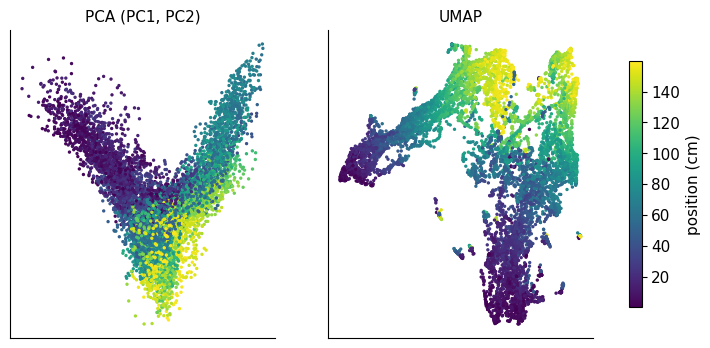

In [35]:
# §B1.4 · PCA of the 120-neuron activity; kNN decoding from 3 PCs; UMAP (if available) coloured by position
Zsp = StandardScaler().fit_transform(Xsp)
pca10 = PCA(n_components=10, random_state=SEED).fit(Zsp)
evr = 100 * pca10.explained_variance_ratio_
print(f"variance explained by PC1-PC3: {evr[0]:.1f}%, {evr[1]:.1f}%, {evr[2]:.1f}%  · lecture run "
      f"{EXPECTED['embedding.pca_evr_pc1_pc2_pc3_percent']}")
CHECK["embedding.pca_evr_pc1_pc2_pc3_percent"] = [float(v) for v in evr[:3]]
p3 = oof_predict(make_pipeline(StandardScaler(), PCA(3, random_state=SEED), KNeighborsRegressor(n_neighbors=10)),
                 Xsp, pos, CV_BLOCKS)
show("kNN from 3 PCs, contiguous blocks: R²", r2_score(pos, p3), key="embedding.honest_knn10_from_pca3d.r2_pooled")
try:
    import umap
except ImportError:
    umap = None
pcs = pca10.transform(Zsp)
ncol = 2 if umap is not None else 1
fig, axs = plt.subplots(1, ncol, figsize=(4.7 * ncol, 4))
axs = np.atleast_1d(axs)
sc_ = axs[0].scatter(pcs[:, 0], pcs[:, 1], c=pos, s=2, cmap="viridis"); axs[0].set_title("PCA (PC1, PC2)", fontsize=11)
if umap is not None:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        U = umap.UMAP(n_neighbors=30, n_components=2, random_state=SEED).fit_transform(Zsp)
    axs[1].scatter(U[:, 0], U[:, 1], c=pos, s=2, cmap="viridis"); axs[1].set_title("UMAP", fontsize=11)
else:
    print("umap-learn is not installed here: UMAP skipped (it is preinstalled on Colab)")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(sc_, ax=axs, shrink=0.8, label="position (cm)")
plt.show()

**What you should see.** The first 3 PCs explain only 13.5% of the variance,
yet kNN from those 3 numbers still reads the position (R² 0.82). The UMAP
map is a curve ordered by position (colour): the population activity lives on a low-dimensional track.

**§B1.5 · Connectivity features: which cells fire together?** A graph of the cells: edges = the 5% most correlated pairs of cells.

edges (top 5% of pairs): 351  · lecture run 351
median peak distance, edges (cm): 10  · lecture run 10
median peak distance, all pairs (cm): 60  · lecture run 60
random sets of pairs: 95% of their medians between 50 and 65 cm
edges within 20 cm: 0.70  · lecture run 0.70


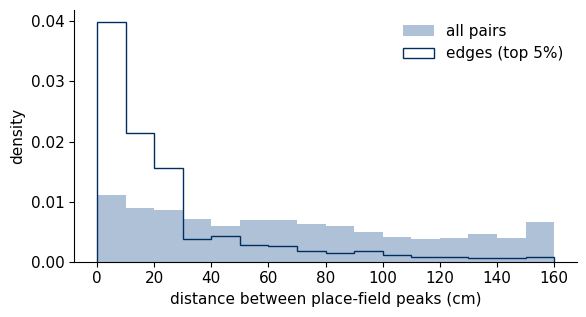

In [36]:
# §B1.5 · Co-activity graph: do strongly correlated cells have nearby place fields?
active = np.flatnonzero(S_run.sum(0) > 0)
Rc = np.corrcoef(Xsp[:, active].T)
iu_c = np.triu_indices(len(active), 1)
r_pairs = Rc[iu_c]
thr_c = np.quantile(r_pairs, 0.95)
is_edge = r_pairs > thr_c
pk = peak_pos["both"][active]
dpk = np.abs(pk[iu_c[0]] - pk[iu_c[1]])                     # distance between the two place-field peaks (cm)
rng = np.random.default_rng(SEED)
null_med = np.array([np.median(dpk[rng.choice(len(dpk), is_edge.sum(), replace=False)]) for _ in range(10000)])
show("edges (top 5% of pairs)", is_edge.sum(), key="graph.n_edges", nd=0)
show("median peak distance, edges (cm)", np.median(dpk[is_edge]), key="graph.median_peak_distance_cm_edges", nd=0)
show("median peak distance, all pairs (cm)", np.median(dpk), key="graph.median_peak_distance_cm_all_pairs", nd=0)
print(f"random sets of pairs: 95% of their medians between {np.percentile(null_med, 2.5):.0f} and "
      f"{np.percentile(null_med, 97.5):.0f} cm")
show("edges within 20 cm", (dpk[is_edge] <= 20).mean(), key="graph.frac_edges_within_20cm")
fig, ax = plt.subplots(figsize=(6, 3.3))
bins_ = np.arange(0, 165, 10)
ax.hist(dpk, bins=bins_, density=True, color=GREYBLUE, alpha=0.8, label="all pairs")
ax.hist(dpk[is_edge], bins=bins_, density=True, histtype="step", color=NAVY, lw=2.5, label="edges (top 5%)")
ax.set_xlabel("distance between place-field peaks (cm)"); ax.set_ylabel("density"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What you should see.** 351 edges (r > 0.157); the cells they join have place
fields a median 10 cm apart, against 60
cm for all pairs (random sets of pairs: 50–65
cm); 70% of edges join cells within 20 cm vs
25% of all pairs. Cells that fire at nearby places co-fire — but a
correlation is not a synapse.

**Q3:** within about 13 cm, on stretches of time the model never
saw, from 120 neurons.

## §B2 · Decoding objects from fMRI: hold out whole runs

Haxby et al. 2001 (CC BY-SA 3.0): one person views pictures of 8 categories (faces, houses, cats, bottles, scissors,
shoes, chairs, scrambled pictures) in 12 runs; we use subject 2, 464 voxels of the
ventral temporal cortex, one image every 2.5 s, rest images removed
(108 images per category). Chance = 1/8 = 0.125.

**Predict:** *leave one run out vs shuffled images: which is higher, and why?*

leave one run out: 0.73 ± 0.07 (73%)  · lecture run 0.73 ± 0.07
shuffled images: 0.85 ± 0.03 (85%)  · lecture run 0.85 ± 0.03
recall per category (leave one run out): bottle 0.57, cat 0.81, chair 0.67, face 0.82, house 0.95, scissors 0.46, scrambledpix 0.88, shoe 0.64


face vs house, leave one run out: 1.00 ± 0.00 (100%)  · lecture run 1.00 ± 0.00
bottle vs scissors, leave one run out: 0.70 ± 0.28 (70%)  · lecture run 0.70 ± 0.28


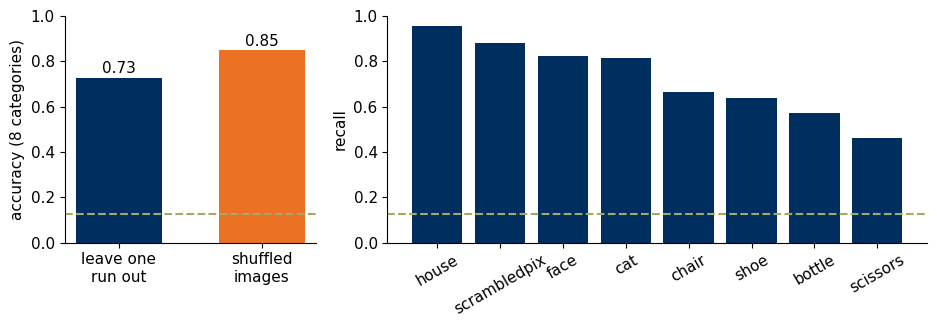

In [37]:
# §B2 · 8-way decoding: leave one run out vs 12 folds of shuffled images
hx = np.load(get_repo_file("fmri_haxby_subj2_vt.npz"), allow_pickle=False)
keep_h = hx["labels"] != "rest"
Xh, yh, gh = hx["X"][keep_h].astype(float), hx["labels"][keep_h], hx["runs"][keep_h]
haxby_clf = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))])
acc_logo = cross_val_score(haxby_clf, Xh, yh, groups=gh, cv=LeaveOneGroupOut())
acc_kf = cross_val_score(haxby_clf, Xh, yh, cv=KFold(12, shuffle=True, random_state=SEED))
show_cv("leave one run out", acc_logo, prefix="haxby_8way_leave_one_run_out_acc")
show_cv("shuffled images", acc_kf, prefix="haxby_8way_shuffled_kfold12_volumes_acc")
pred_logo = cross_val_predict(haxby_clf, Xh, yh, groups=gh, cv=LeaveOneGroupOut())
cats = np.unique(yh)
recall = np.diag(confusion_matrix(yh, pred_logo, labels=cats, normalize="true"))
print("recall per category (leave one run out):", ", ".join(f"{c} {r:.2f}" for c, r in zip(cats, recall)))
for c, r in zip(cats, recall):
    CHECK[f"haxby_8way_logo_recall_{c}"] = float(r)
for a_, b_ in (("face", "house"), ("bottle", "scissors")):
    m_ = np.isin(yh, (a_, b_))
    sc = cross_val_score(haxby_clf, Xh[m_], yh[m_], groups=gh[m_], cv=LeaveOneGroupOut())
    show_cv(f"{a_} vs {b_}, leave one run out", sc, prefix=f"haxby_{a_}_vs_{b_}_leave_one_run_out_acc")
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4), gridspec_kw={"width_ratios": [0.7, 1.5]})
for k, (sc, col) in enumerate(((acc_logo, NAVY), (acc_kf, ORANGE))):
    axs[0].bar(k, sc.mean(), color=col, width=0.6); axs[0].text(k, sc.mean() + 0.02, f"{sc.mean():.2f}", ha="center")
axs[0].axhline(1 / 8, color=OLIVE, ls="--"); axs[0].set_ylim(0, 1)
axs[0].set_xticks([0, 1], ["leave one\nrun out", "shuffled\nimages"]); axs[0].set_ylabel("accuracy (8 categories)")
o_ = np.argsort(-recall)
axs[1].bar(range(8), recall[o_], color=NAVY); axs[1].axhline(1 / 8, color=OLIVE, ls="--")
axs[1].set_xticks(range(8), cats[o_], rotation=30); axs[1].set_ylabel("recall"); axs[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

**What you should see.** Leave one run out: 0.73 ±
0.07; shuffled images: 0.85 ±
0.03 (+12 points). Neighbouring images
share the slow BOLD response (it peaks about 5 s later, two images), so a shuffled split tests on near-copies of
training images. Houses (0.95) and faces (0.82) are easy,
scissors (0.46) and bottles (0.57) hard; face vs
house 1.00, bottle vs scissors
0.70 ± 0.28.

**Trust check · TIME**, with SPLIT by run.

## §B3 · Clustering sleep without the rules

Experts score sleep in 30-s epochs with rules: W awake · N1 drowsy · N2 light sleep with spindles · N3 deep sleep with
slow waves · REM dreaming, with rapid eye movements (these 1990s recordings were scored with the older R&K rules,
mapped here to five stages, S3 + S4 = N3). Decat et al. 2022 (Sleep Medicine 98:39–52) clustered sleep epochs on more
than 7,700 time-series features without any scoring rule; the clusters overlapped substantially with visual scoring and
also showed structure inside the stages. Here is a tiny, transparent version: **clustering as compression**, each 30-s
epoch (12 numbers: relative band power in 5 bands at two electrodes, Fpz-Cz and Pz-Oz, plus their total power) → 1 of
5 prototypes. Data: Sleep-EDF (Kemp et al. 2000; PhysioNet; ODC-By), 8 nights,
7,647 epochs: W 1,287 · N1 677 · N2 3,489 · N3 963 · REM 1,231. The stage labels are used **only to evaluate**.

**Predict:** *how many groups does the data want?*

best k by silhouette: 5  · lecture run 5
silhouette at k = 5: 0.324  · lecture run 0.324


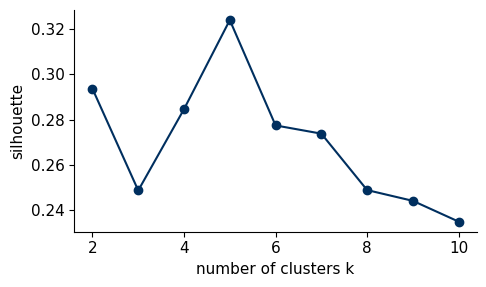

In [38]:
# §B3.1 · Features per night z-scored; silhouette for k = 2..10 (no labels used)
sl = np.load(get_repo_file("sleep8_feat.npz"), allow_pickle=False)
F_sleep, y_sleep, night = sl["F"].astype(float), sl["y"], sl["g"]
STAGES = ["W", "N1", "N2", "N3", "REM"]
Z_sleep = np.empty_like(F_sleep)
for s in np.unique(night):                                   # remove night-to-night offsets
    m_ = night == s
    Z_sleep[m_] = (F_sleep[m_] - F_sleep[m_].mean(0)) / (F_sleep[m_].std(0) + 1e-12)
rng_sleep = np.random.default_rng(SEED)
sub_s = rng_sleep.choice(len(Z_sleep), size=4000, replace=False)
sil_k = {k: silhouette_score(Z_sleep[sub_s], KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z_sleep)[sub_s])
         for k in range(2, 11)}
for k, v in sil_k.items():
    CHECK[f"silhouette_by_k.{k}"] = float(v)
best_k = max(sil_k, key=sil_k.get)
show("best k by silhouette", best_k, key="best_k_by_silhouette", nd=0)
show("silhouette at k = 5", sil_k[5], key="silhouette_by_k.5", nd=3)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(list(sil_k), list(sil_k.values()), "o-", color=NAVY)
ax.set_xlabel("number of clusters k"); ax.set_ylabel("silhouette")
plt.tight_layout(); plt.show()

ARI with the expert stages: 0.259  · lecture run 0.259
NMI: 0.417  · lecture run 0.417
purity: 0.635  · lecture run 0.635
ARI of a random relabelling: 0.000  · lecture run 0.000


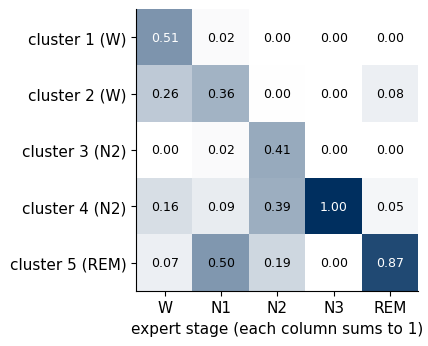

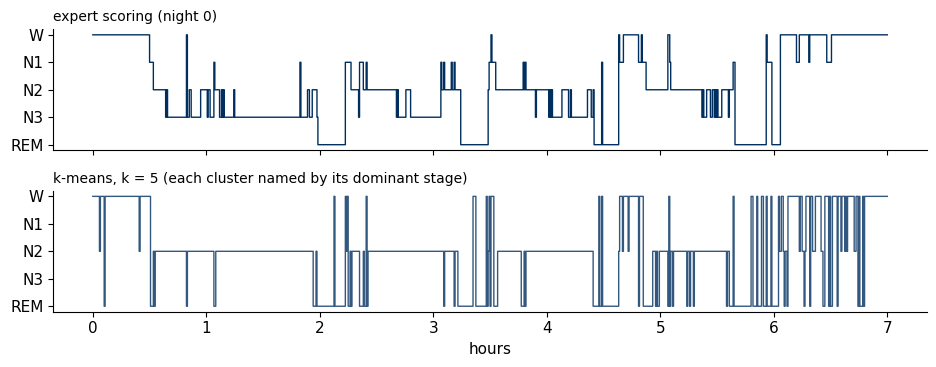

In [39]:
# §B3.2 · k = 5: clusters vs the expert stages
km5 = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit_predict(Z_sleep)
T5 = np.array([[((km5 == c) & (y_sleep == j + 1)).sum() for j in range(5)] for c in range(5)])
order5 = np.argsort([np.argmax(r) * 100 - r.max() / r.sum() for r in T5])      # clusters sorted by dominant stage
T5s = T5[order5]
show("ARI with the expert stages", adjusted_rand_score(y_sleep, km5), key="k5.ARI", nd=3)
show("NMI", normalized_mutual_info_score(y_sleep, km5), key="k5.NMI", nd=3)
show("purity", T5s.max(1).sum() / T5s.sum(), key="k5.purity", nd=3)
show("ARI of a random relabelling", adjusted_rand_score(y_sleep, rng_sleep.permutation(km5)), key="ARI_random_relabel_k5", nd=3)
share_st = T5s / T5s.sum(0, keepdims=True)                 # how each stage spreads over the clusters
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.imshow(share_st, cmap=WHITE_NAVY, vmin=0, vmax=1)
ax.set_xticks(range(5), STAGES)
ax.set_yticks(range(5), [f"cluster {k + 1} ({STAGES[np.argmax(r)]})" for k, r in enumerate(T5s)])
for i_ in range(5):
    for j_ in range(5):
        ax.text(j_, i_, f"{share_st[i_, j_]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if share_st[i_, j_] > 0.5 else "black")
ax.set_xlabel("expert stage (each column sums to 1)")
plt.tight_layout(); plt.show()
m0 = night == np.unique(night)[0]                          # night 0: expert hypnogram above, clusters below
dom = np.array([np.argmax(T5[c]) + 1 for c in range(5)])   # each cluster named by its dominant stage
hours = np.arange(m0.sum()) * 0.5 / 60
fig, axs = plt.subplots(2, 1, figsize=(9.5, 3.8), sharex=True)
axs[0].step(hours, -y_sleep[m0], where="post", color=NAVY, lw=1)
axs[1].step(hours, -dom[km5[m0]], where="post", color=STEEL, lw=1)
axs[0].set_title("expert scoring (night 0)", loc="left", fontsize=10)
axs[1].set_title("k-means, k = 5 (each cluster named by its dominant stage)", loc="left", fontsize=10)
for ax in axs:
    ax.set_yticks(-np.arange(1, 6), STAGES)
axs[1].set_xlabel("hours")
plt.tight_layout(); plt.show()

**What you should see.** The silhouette peaks at k = 5 (0.324), but the
peak is shallow (0.294 at k = 2). With k = 5 the clusters **partly match** the big stages
without any scoring rule: ARI 0.26 (random relabelling 0.00), NMI 0.42,
purity 0.64. A wake cluster is 98% wake; all N3 falls in one
cluster, which also takes 39% of N2; 87%
of REM sits in one cluster that half of N1 joins (EEG alone, without eye and chin channels, cannot separate them well);
N2 is split over two clusters. ARI 0.26 is far from 1. (k = 8 gives ARI 0.30.)

## §B4 · A Riemannian EEG model: covariance → tangent space → linear model

The recipe of §6.4, now for EEG: each 2-s window → a 64 × 64 covariance matrix (how the channels vary together) →
tangent space → logistic regression, tested on new people. We use nilearn's tangent space (no extra package).

In [40]:
# §B4 · Tangent-space model on the raw EEG windows (main path of §0 only; takes a little longer)
need("y")
if X is None:
    print("needs the raw EEG windows (main path of §0) — skipped")
else:
    tangent_eeg = Pipeline([("connectome", ConnectivityMeasure(kind="tangent", vectorize=True, discard_diagonal=True)),
                            ("scale", StandardScaler()), ("lr", LogisticRegression(C=1.0, max_iter=5000))])
    acc_tan = cross_val_score(tangent_eeg, list(X.transpose(0, 2, 1)), y, groups=g, cv=CV_PERSON)
    show_cv("tangent space, new people", acc_tan, prefix="clf_tangent_nilearn_honest")
    print("   folds:", np.round(acc_tan, 2), "· lecture run", EXPECTED["clf_tangent_nilearn_honest_folds"])
    if globals().get("acc_full") is not None:
        print(f"better than the spectrum model of §2.2 in {(acc_tan > acc_full).sum()} of 5 folds "
              f"(+{100 * (acc_tan.mean() - acc_full.mean()):.1f} points)")

tangent space, new people: 0.79 ± 0.07 (79%)  · lecture run 0.79 ± 0.07
   folds: [0.72 0.8  0.78 0.92 0.75] · lecture run [0.7167, 0.7958, 0.7792, 0.9167, 0.75]
better than the spectrum model of §2.2 in 4 of 5 folds (+4.4 points)


**What you should see.** 0.79 ± 0.07, close to the
spectrum model of §2.2 (0.75) and a little better
(+4 points; better in 4
of 5 folds and, in the lecture run, for 12 of 20
people) — not a big win.

## §B5 · Leakage and luck on pure noise

**§B5.1 · Choose features with the test data.** 100 examples × 10,000
random features, labels 50/50: there is **no signal** at all. (a) Pick the 20 features most
related to the label using *all* the data, then run a 5-fold cross-validation; (b) the same, but the selection happens
*inside* each training fold.

**Predict:** *what accuracy on pure noise, in (a) and (b)?*

(a) selection outside the CV: 0.95 (95%)  · lecture run 0.95
(b) selection inside the CV: 0.54 (54%)  · lecture run 0.54


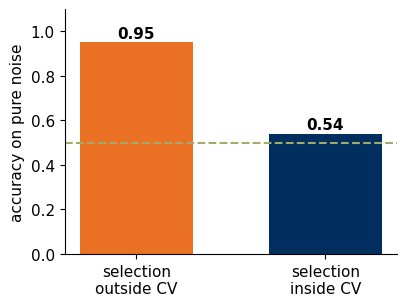

In [41]:
# §B5.1 · Feature selection outside vs inside the cross-validation, on pure noise
rng_l = np.random.default_rng(SEED)
X_noise = rng_l.standard_normal((100, 10000))
y_noise = np.repeat([0, 1], 50)
cv_l = StratifiedKFold(5, shuffle=True, random_state=0)
X_sel = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)       # uses the test labels too
acc_out = cross_val_score(make_clf(), X_sel, y_noise, cv=cv_l)
pipe_in = Pipeline([("select", SelectKBest(f_classif, k=20)), ("scale", StandardScaler()),
                    ("lr", LogisticRegression(C=1.0, max_iter=5000))])
acc_in = cross_val_score(pipe_in, X_noise, y_noise, cv=cv_l)
show("(a) selection outside the CV", acc_out.mean(), key="leakdemo_selection_outside_cv_rep0_mean", pct=True)
show("(b) selection inside the CV", acc_in.mean(), key="leakdemo_selection_inside_cv_rep0_mean", pct=True)
fig, ax = plt.subplots(figsize=(4.2, 3.2))
for k, (v, col) in enumerate(((acc_out.mean(), ORANGE), (acc_in.mean(), NAVY))):
    ax.bar(k, v, color=col, width=0.6); ax.text(k, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold")
ax.axhline(0.5, color=OLIVE, ls="--"); ax.set_ylim(0, 1.1)
ax.set_xticks([0, 1], ["selection\noutside CV", "selection\ninside CV"]); ax.set_ylabel("accuracy on pure noise")
plt.tight_layout(); plt.show()

**What you should see.** (a) 0.95 vs (b) 0.54
on data with no signal; over 20 repetitions, about 0.90 vs
0.50. In real data the same mistake turned a correlation of 0.01 into 0.48
(Rosenblatt et al. 2024). **Trust check · SPLIT:** the test examples helped choose the features.

**§B5.2 · Luck: how high can pure noise score with 20 examples?** Logistic regression on N examples × 20 noise
features, balanced labels, 5-fold cross-validation, repeated 1,000 times, for N = 20 and N = 200.

**Predict:** *with N = 20, how often does pure noise reach 70% accuracy?*

N = 20: SD of the accuracy: 0.138  · lecture run 0.138
N = 20: 95th percentile: 0.700  · lecture run 0.700
N = 20: best of 1,000: 0.900  · lecture run 0.900
N = 20: share of runs at or above 0.70: 0.102  · lecture run 0.102
N = 20: accuracy needed for p < 0.05 (binomial test): 0.750  · lecture run 0.750
N = 200: SD of the accuracy: 0.045  · lecture run 0.045
N = 200: 95th percentile: 0.570  · lecture run 0.570
N = 200: best of 1,000: 0.635  · lecture run 0.635
N = 200: share of runs at or above 0.70: 0.000  · lecture run 0.000
N = 200: accuracy needed for p < 0.05 (binomial test): 0.565  · lecture run 0.565


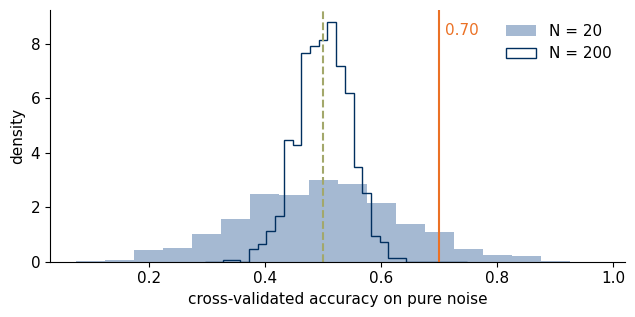

In [42]:
# §B5.2 · 1,000 repetitions of cross-validated logistic regression on noise, N = 20 and N = 200 (takes a little longer)
rng_n = np.random.default_rng(SEED)
noise_acc = {}
for N in (20, 200):
    yN = np.repeat([0, 1], N // 2)
    noise_acc[N] = np.array([cross_val_score(make_clf(), rng_n.standard_normal((N, 20)), yN,
                                             cv=StratifiedKFold(5, shuffle=True, random_state=rep)).mean()
                             for rep in range(1000)])
for N in (20, 200):
    a = noise_acc[N]
    show(f"N = {N}: SD of the accuracy", a.std(), key=f"noise_N{N}_acc_sd", nd=3)
    show(f"N = {N}: 95th percentile", np.percentile(a, 95), key=f"noise_N{N}_acc_p95", nd=3)
    show(f"N = {N}: best of 1,000", a.max(), key=f"noise_N{N}_acc_max", nd=3)
    show(f"N = {N}: share of runs at or above 0.70", (a >= 0.70).mean(), key=f"noise_N{N}_frac_reps_acc_ge_0_70", nd=3)
    k_min = next(k for k in range(N + 1) if binom.sf(k - 1, N, 0.5) < 0.05)     # smallest k with P(X >= k) < 0.05
    show(f"N = {N}: accuracy needed for p < 0.05 (binomial test)", k_min / N,
         key=f"noise_N{N}_binomial_p05_threshold_strict_acc", nd=3)
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.hist(noise_acc[20], bins=np.arange(0.075, 1.0, 0.05), density=True, color=GREYBLUE, alpha=0.9, label="N = 20")
ax.hist(noise_acc[200], bins=np.arange(0.2975, 0.75, 0.015), density=True, histtype="step", color=NAVY, lw=2,
        label="N = 200")
ax.axvline(0.5, color=OLIVE, ls="--"); ax.axvline(0.7, color=ORANGE, lw=1.5)
ax.text(0.71, ax.get_ylim()[1] * 0.9, "0.70", color=ORANGE)
ax.set_xlabel("cross-validated accuracy on pure noise"); ax.set_ylabel("density"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What you should see.** With N = 20 the accuracy on noise has an SD of 0.14; the 95th percentile is
0.70, 10% of runs reach 0.70 and the best reaches
0.90. With N = 200: SD 0.045, 95th percentile 0.57, best
0.635, none at 0.70. A one-sided binomial test at p < 0.05 needs
15 of 20 correct (0.75)
but only 113 of 200 (0.565).
**Trust check · UNCERTAINTY:** small samples make big numbers by luck.

## §B6 · Train a logistic regression by hand: gradient descent

A model learns by changing its parameters to lower the loss: θ* = argmin over θ of L(θ). For the one-feature model of
§2.3, θ = (w, b) and L = the average cross-entropy on the training windows. **Gradient descent:** start at w = b = 0,
compute the slope of L with respect to w and b, take a small step downhill (the step size is the **learning rate**),
repeat. At w = b = 0 every probability is 0.5, so the loss starts at ln 2 ≈ 0.693 for any data. We
leave out scikit-learn's small penalty on w (`C = 1`): with 1,200 windows it changes w by less than 0.01.

**Predict:** *how many steps until the loss stops moving? Will you land on scikit-learn's w and b?*

loss at the start: 0.6931  · lecture run 0.6931
loss after 5 steps: 0.6288  · lecture run 0.6288
loss after 20 steps: 0.6014  · lecture run 0.6014
loss after 100 steps: 0.5998  · lecture run 0.5998
w after 100 steps: 0.9713  · lecture run 0.9713
b after 100 steps: 0.0129  · lecture run 0.0129
scikit-learn without penalty: w: 0.9715  · lecture run 0.9715
scikit-learn without penalty: b: 0.0129  · lecture run 0.0129
accuracy on the training windows: 0.65 (65%)  · lecture run 0.65


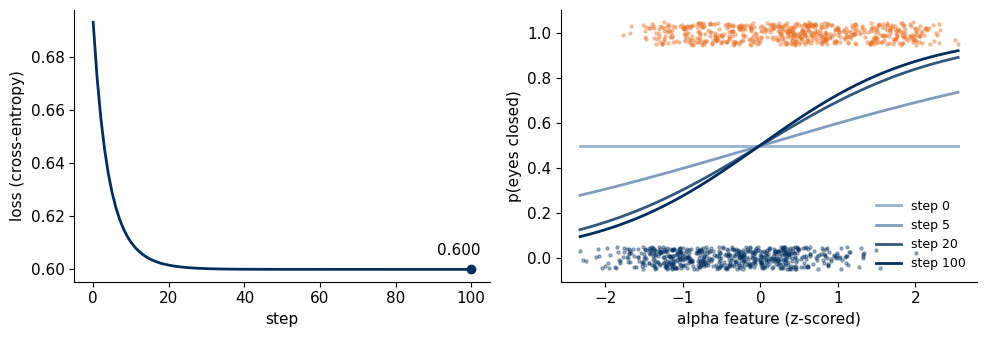

In [43]:
# §B6 · Gradient descent for p = sigmoid(w z + b), z = the z-scored alpha feature of §2.1 (numpy only)
need("F_one")
x1 = F_one[:, 0]
zf = (x1 - x1.mean()) / x1.std()                    # z-score, as StandardScaler does
LR_STEP, N_STEPS = 0.5, 100                         # learning rate, number of steps


def loss(w_, b_):
    s_ = w_ * zf + b_
    return np.mean(np.logaddexp(0, s_) - y * s_)    # cross-entropy, written in a numerically safe way


w_, b_ = 0.0, 0.0
hist = [(w_, b_, loss(w_, b_))]
for step in range(N_STEPS):
    p_ = 1 / (1 + np.exp(-(w_ * zf + b_)))          # current probabilities of "eyes closed"
    dw, db = np.mean((p_ - y) * zf), np.mean(p_ - y)  # slopes of the loss
    w_, b_ = w_ - LR_STEP * dw, b_ - LR_STEP * db   # one step downhill
    hist.append((w_, b_, loss(w_, b_)))
hist = np.array(hist)
show("loss at the start", hist[0, 2], key="lr1_loss_iter0", nd=4)
show("loss after 5 steps", hist[5, 2], key="lr1_loss_iter5", nd=4)
show("loss after 20 steps", hist[20, 2], key="lr1_loss_iter20", nd=4)
show("loss after 100 steps", hist[-1, 2], key="lr1_final_loss", nd=4)
show("w after 100 steps", hist[-1, 0], key="lr1_final_w", nd=4)
show("b after 100 steps", hist[-1, 1], key="lr1_final_b", nd=4)
sk = LogisticRegression(penalty=None, tol=1e-10, max_iter=5000).fit(zf[:, None], y)
show("scikit-learn without penalty: w", sk.coef_[0, 0], key="lr1_sklearn_penalty_none_w", nd=4)
show("scikit-learn without penalty: b", sk.intercept_[0], key="lr1_sklearn_penalty_none_b", nd=4)
show("accuracy on the training windows", ((hist[-1, 0] * zf + hist[-1, 1] >= 0) == y).mean(), key="lr1_train_acc", pct=True)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(hist[:, 2], color=NAVY, lw=2)
axs[0].scatter([N_STEPS], [hist[-1, 2]], color=NAVY, zorder=3)
axs[0].annotate(f"{hist[-1, 2]:.3f}", (N_STEPS, hist[-1, 2]), xytext=(-25, 10), textcoords="offset points")
axs[0].set_xlabel("step"); axs[0].set_ylabel("loss (cross-entropy)")
rng = np.random.default_rng(SEED)
for lab, col in ((0, EO_C), (1, EC_C)):
    axs[1].scatter(zf[y == lab], lab + rng.uniform(-0.05, 0.05, (y == lab).sum()), s=5, color=col, alpha=0.35)
zz = np.linspace(zf.min(), zf.max(), 200)
for it, col in zip((0, 5, 20, N_STEPS), (GREYBLUE, "#7F9CBF", STEEL, NAVY)):
    axs[1].plot(zz, 1 / (1 + np.exp(-(hist[it, 0] * zz + hist[it, 1]))), color=col, lw=2, label=f"step {it}")
axs[1].set_xlabel("alpha feature (z-scored)"); axs[1].set_ylabel("p(eyes closed)"); axs[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
save_check()   # for the lecturer's automatic check only

**What you should see.** The loss falls from 0.693 to 0.629 after 5 steps and
0.601 after 20, and stops moving at 0.600 (within 0.001 of the best possible after
23 steps). The sigmoid tilts and settles. After 100 steps w = 0.971
and b = 0.013, the same as scikit-learn without the penalty (0.972,
0.013). The same loop, with millions of parameters and backpropagation to get the slopes,
trains the CNN of Part 3. Extra exercise 11 changes the learning rate.

## Extra (optional) exercises

Each names the variable or cell to change. There is no single right answer: write down what you expect first.

1. **Window length.** Set `WIN_S = 1` or `4` in §0.2, re-run §0.4, §1.3 and §2. What happens to the person-grouped and
   the shuffled accuracy, and to the gap between them? Why? (Main path only.)
2. **Which band carries the decision?** Keep only beta (13–30 Hz) for all channels, or remove 8–13 Hz everywhere
   (use `in_band()` as in §5.1). Does the honest accuracy drop to chance?
3. **Which channels does the model use?** Fit `make_clf()` on `F_full`, reshape its weights to 64 × 40 and plot the
   alpha-band weights as a topomap (`mne.viz.plot_topomap`, as in §1.3). Why are weights not the same as "where the
   brain signal is" (Haufe et al. 2014)?
4. **Regularization.** In §2.2, use `make_clf(C=0.001)`, `0.01`, `1`, `100`. How do the training and the test
   accuracy move? Where is the gap smallest?
5. **One new patient.** Per-person normalisation (§3.3) needs both conditions from the new person. What would a clinic
   have to record for it to be legitimate? What could you do with one recording only?
6. **Name the trust check.** For each inflated result (§2.4 shuffled windows, §6.3 "always child" accuracy, §B2
   shuffled images, §B1.3 shuffled bins, §B5.1 selection outside the CV), which trust check fails, and what leaked or
   was hidden?
7. **A different graph.** In §6.4 add `"partial correlation"` (lecture run: balanced accuracy
   0.83 ± 0.10, AUC
   0.94). Partial correlation removes indirect links: why can it predict
   *worse*? Then build one person's sparse graph with
   `ConnectivityMeasure(cov_estimator=GraphicalLassoCV(), kind="precision")` (import `GraphicalLassoCV` from
   `sklearn.covariance`): how many of the 741 edges survive?
8. **Graphs are fragile.** The per-window envelope correlation is slightly *lower* with eyes closed
   (0.41 vs 0.43,
   10/20 people), while one correlation over the whole minute is slightly
   *higher* (0.48 vs
   0.46, 13/20,
   p = 0.26). What does this say about claims like "the network is
   denser with eyes closed"? Which measure that ignores zero-lag mixing would you try?
9. **More people.** Change `SUBJECTS = range(1, 41)` in §0.2 (another 51 MB) and re-run. Does the honest accuracy rise,
   and does the gap to the shuffled split shrink? (Main path only.)
10. **Be the first layer of a CNN.** Build a 10-Hz kernel (for example 0.5 s of a sine wave under a Hann window) and
    slide it over Oz with `np.convolve` for eyes open and closed (S007). Compare the size of the output. What would a
    CNN have to learn to find this kernel by itself?
11. **Learning rate.** In §B6, multiply `LR_STEP` by 10, then divide it by 10. What happens to the loss curve? Why does
    a too-large step fail?
12. **Clustering choices.** In §3.2 try k = 3, 4, 10, and k = 20 on the per-person z-scored features (lecture run: ARI
    with eyes 0.08, with person 0.025).
    In §B3 try k = 8 (ARI 0.30) and remove the per-night z-scoring. Which choices change the story?
13. **Fewer neurons.** In §B1.3 decode the position from 10, 30 and 60 random neurons. How does R² scale?
14. **Age without motion.** Within children, age and motion are barely related (Spearman
    −0.07). Does §7.2's children-only model survive adding FD as a feature?

## Credits and references

**Data.** EEG Motor Movement/Imagery dataset — Schalk et al. 2004, *IEEE Trans Biomed Eng* 51:1034; PhysioNet
(Goldberger et al. 2000), ODC-By 1.0 · Development fMRI — Richardson et al. 2018, *Nat Commun* 9:1027; OpenNeuro
ds000228; nilearn derivative, CC BY 4.0 · Haxby et al. 2001, *Science* 293:2425, CC BY-SA 3.0 · Sleep-EDF — Kemp et al.
2000, *IEEE Trans Biomed Eng* 47:1185, ODC-By 1.0 · Rat hippocampus — Grosmark & Buzsáki 2016, *Science* 351:1440;
DANDI 000044, CC BY 4.0.

**Methods.** MSDL atlas — Varoquaux et al. 2011; BASC — Bellec et al. 2010; Craddock et al. 2012 · tangent space —
Barachant et al. 2012; Dadi et al. 2019 · t-SNE — van der Maaten & Hinton 2008; UMAP — McInnes et al. 2018; ARI —
Hubert & Arabie 1985 · sleep clustering — Decat et al. 2022 · leakage — Brookshire et al. 2024; Rosenblatt et al. 2024;
Varoquaux 2018 · model weights — Haufe et al. 2014.

**Software.** MNE-Python (Gramfort et al. 2013), scikit-learn (Pedregosa et al. 2011), nilearn (Abraham et al. 2014),
numpy, scipy, pandas, matplotlib, pooch.

Full references with links are on the course resources page. Repository: <https://github.com/gon-uri/ITBA2026>.